#  DRL Project — DQN vs PPO on MinAtar
**Research questions:**
"how do the key mechanisms of DQN and PPO influence exploration and performance? Does combining the best hyperparameters found experimentally produce better results than standard configurations?"


**Experiments:**

- Exp 1 — DQN Epsilon Scheduling          (Exploration)

- Exp 2 — DQN Replay Buffer Ablation      (Stability & Sample Efficiency)

- Exp 3 — PPO Entropy Bonus               (Exploration)

- Exp 4 — PPO Clip Parameter Ablation     (Stability & Conservativity)

- Exp 5 — DQN Target Update Frequency     (Stability)

- Exp 6 — PPO GAE Lambda                  (Bias-Variance Tradeoff)

- Exp 7 — Heatmaps + 1M step comparison   (Cross-algorithm)

Base implementations from CleanRL: https://github.com/vwxyzjn/cleanrl

Original additions:
- Configurable hyperparameter dictionary replacing CleanRL's hardcoded values
- StateVisitationTracker for exploration heatmaps
- Replay buffer ablation (buffer_size=0)
- No-clip ablation (clip_coef=1.0)
- No-entropy ablation (ent_coef=0.0)
- W&B logging of custom metrics
- Area under curve for sample efficiency (Exp 7)
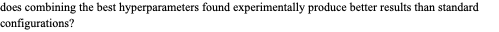
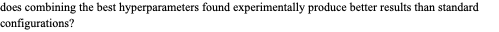
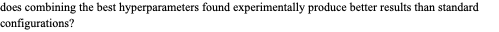
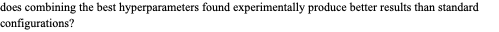

In [1]:
# Install dependencies 
!pip install minatar wandb torch numpy matplotlib

In [2]:
# Imports & path setup 
import sys
import os
import json
import numpy as np
import wandb
 
sys.path.insert(0, '/kaggle/input/datasets/fedeant0/dqnvsppo')
 
from drl_utils import (DEVICE, MinAtarEnv, StateVisitationTracker,
                        plot_returns, plot_returns_with_std,
                        summarise_results, sample_efficiency_summary)
from dqn import train_dqn
from ppo import train_ppo
 
print(f"Device: {DEVICE}")

[utils] Using device: cuda
Device: cuda


In [3]:
# W&B login 
from kaggle_secrets import UserSecretsClient
secrets = UserSecretsClient()
wandb.login(key=secrets.get_secret("WANDB_API_KEY"))

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: federico-antolini723 (federico-antolini723-maastricht-univeristy) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [17]:
# Recover results from W&B (run once after losing local JSON) 
# Skip this cell if you already have results in SAVE_DIR.
 
def recover_from_wandb(project: str, save_dir: str):
    """
    Download episode_return history from all W&B runs and save as JSON.
    Run name format: {algo}_{label}_s{seed}  e.g. dqn_eps_aggressive_s0
    """
    api  = wandb.Api()
    runs = api.runs(project)
    os.makedirs(save_dir, exist_ok=True)
 
    for run in runs:
        print(f"Downloading {run.name}...")
        history = run.history(keys=["episode_return"], pandas=False, samples=20000)
        returns = [row["episode_return"] for row in history
                   if "episode_return" in row]
        if returns:
            path = os.path.join(save_dir, f"{run.name}.json")
            with open(path, "w") as f:
                json.dump(returns, f)
            print(f"  -> {len(returns)} episodes saved")
 
# Uncomment to recover:
recover_from_wandb(
     project="federico-antolini723-maastricht-univeristy/project_DQNvsPPO",
     save_dir="/kaggle/working/results"
)



  -> 9566 episodes saved
  -> 9645 episodes saved
  -> 9690 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 8150 episodes saved
  -> 7711 episodes saved
  -> 8276 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 10000 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 episodes saved
  -> 3907 epi

In [6]:
# Save/Load utilities 
SAVE_DIR = '/kaggle/working/results'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"Results will be saved to: {SAVE_DIR}")
 
def save_run(exp_id: str, label: str, seed: int, returns: list):
    path = f"{SAVE_DIR}/{exp_id}_{label}_s{seed}.json"
    with open(path, 'w') as f:
        json.dump(returns, f)
    print(f"  [SAVED] {path}")
 
def load_run(exp_id: str, label: str, seed: int):
    path = f"{SAVE_DIR}/{exp_id}_{label}_s{seed}.json"
    if os.path.exists(path):
        with open(path, 'r') as f:
            return json.load(f)
    return None
 
def load_experiment(exp_id: str, variants: list, seeds: list):
    results = {}
    for v in variants:
        label = v["label"]
        runs  = []
        for seed in seeds:
            r = load_run(exp_id, label, seed)
            if r is not None:
                runs.append(r)
                print(f"  [LOADED] {exp_id} | {label} | seed={seed}")
        if runs:
            results[label] = runs
    return results



Results will be saved to: /kaggle/working/results


In [7]:
# Shared settings 
SEEDS          = [0, 1, 2]
TOTAL_STEPS    = 500_000
GAME           = "breakout"
SNAPSHOT_STEPS = [100_000, 300_000, 500_000]

Step  10,000 | Episodes:  776 | Avg return (last 20): 1.10 | Eps: 0.752
Step  20,000 | Episodes: 1247 | Avg return (last 20): 2.10 | Eps: 0.505
Step  30,000 | Episodes: 1529 | Avg return (last 20): 4.45 | Eps: 0.258
Step  40,000 | Episodes: 1717 | Avg return (last 20): 5.70 | Eps: 0.010
Step  50,000 | Episodes: 1853 | Avg return (last 20): 6.40 | Eps: 0.010


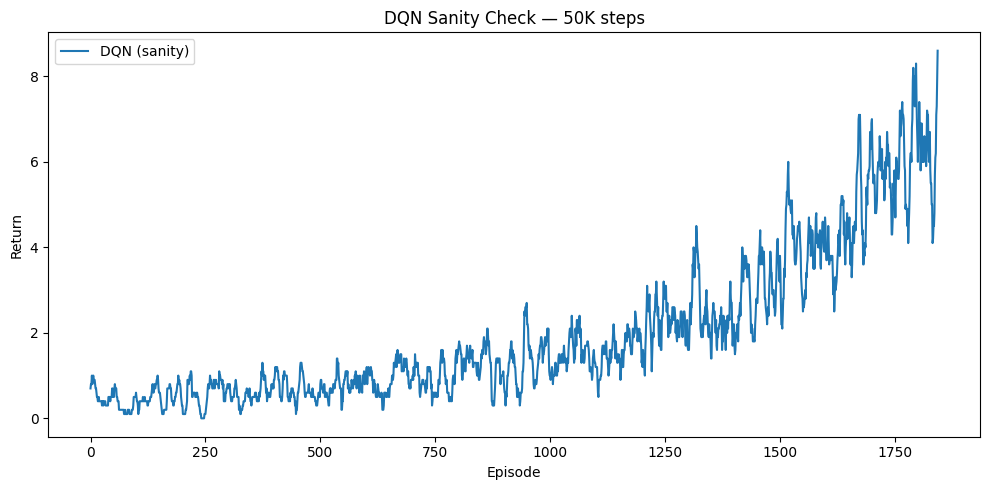

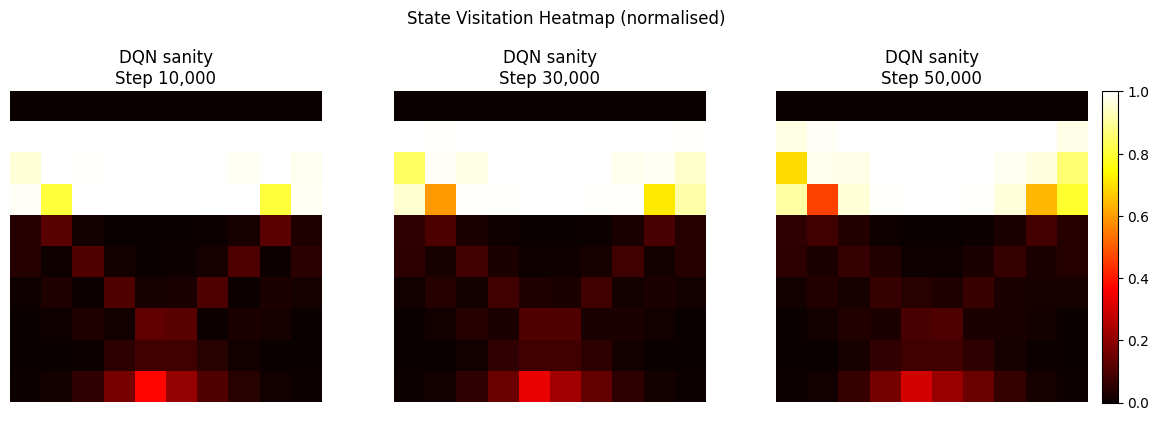

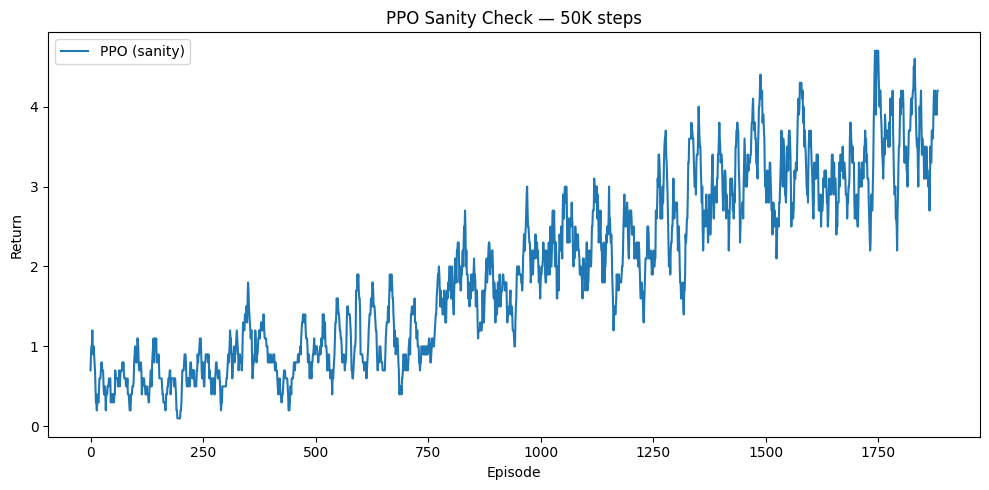

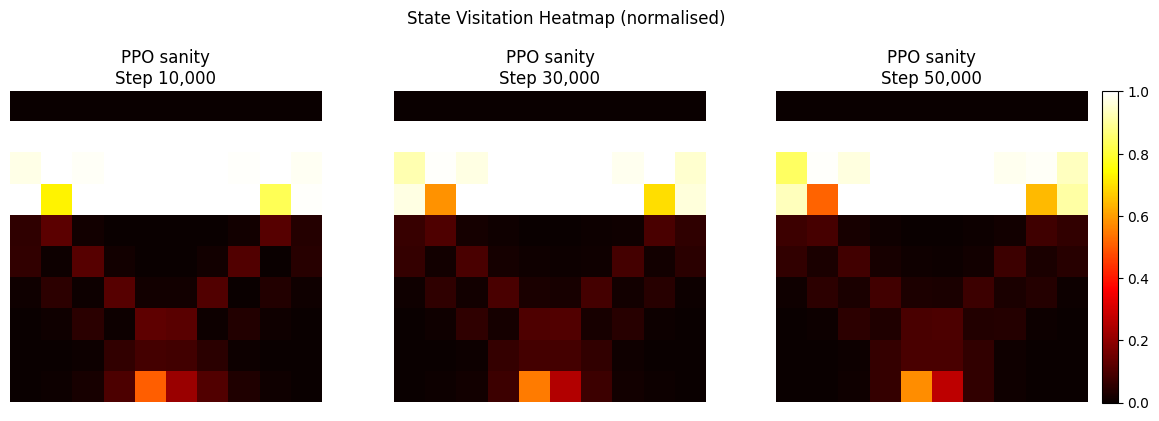

In [7]:
# Sanity checks 
DQN_TEST = {
    "game": GAME, "seed": 42, "total_steps": 50_000,
    "batch_size": 32, "buffer_size": 10_000,
    "lr": 1e-3, "gamma": 0.99,
    "eps_start": 1.0, "eps_end": 0.01, "eps_decay_steps": 40_000,
    "target_update_freq": 500,
    "snapshot_steps": [10_000, 30_000, 50_000],
}
PPO_TEST = {
    "game": GAME, "seed": 42, "total_steps": 50_000,
    "n_steps": 128, "n_epochs": 4, "batch_size": 32,
    "lr": 2.5e-4, "gamma": 0.99, "gae_lambda": 0.95,
    "clip_coef": 0.2, "ent_coef": 0.01, "vf_coef": 0.5, "max_grad_norm": 0.5,
    "snapshot_steps": [10_000, 30_000, 50_000],
}
 
dqn_ret, dqn_tracker = train_dqn(DQN_TEST, run_name="dqn_sanity", use_wandb=False)
plot_returns({"DQN (sanity)": dqn_ret}, title="DQN Sanity Check — 50K steps")
dqn_tracker.plot_snapshots("DQN sanity")
 
ppo_ret, ppo_tracker = train_ppo(PPO_TEST, run_name="ppo_sanity", use_wandb=False)
plot_returns({"PPO (sanity)": ppo_ret}, title="PPO Sanity Check — 50K steps")
ppo_tracker.plot_snapshots("PPO sanity")


[Exp1] eps_aggressive | seed=0


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Step  10,000 | Episodes:  822 | Avg return (last 20): 0.75 | Eps: 0.910
Step  20,000 | Episodes: 1527 | Avg return (last 20): 0.90 | Eps: 0.820
Step  30,000 | Episodes: 2138 | Avg return (last 20): 1.60 | Eps: 0.730
Step  40,000 | Episodes: 2665 | Avg return (last 20): 1.65 | Eps: 0.640
Step  50,000 | Episodes: 3155 | Avg return (last 20): 1.10 | Eps: 0.550
Step  60,000 | Episodes: 3545 | Avg return (last 20): 1.95 | Eps: 0.460
Step  70,000 | Episodes: 3874 | Avg return (last 20): 2.40 | Eps: 0.370
Step  80,000 | Episodes: 4145 | Avg return (last 20): 3.20 | Eps: 0.280
Step  90,000 | Episodes: 4356 | Avg return (last 20): 4.00 | Eps: 0.190
Step 100,000 | Episodes: 4528 | Avg return (last 20): 5.15 | Eps: 0.100
Step 110,000 | Episodes: 4695 | Avg return (last 20): 4.10 | Eps: 0.100
Step 120,000 | Episodes: 4845 | Avg return (last 20): 5.40 | Eps: 0.100
Step 130,000 | Episodes: 4989 | Avg return (last 20): 6.05 | Eps: 0.100
Step 140,000 | Episodes: 5145 | Avg return (last 20): 6.00 | Eps

buffer_size,▁▁▁▁▂▂▂▂▂▂▃▃▄▄▄▄▄▅▅▅████████████████████
episode,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇█
episode_return,▁▁▁▁▁▁▁▁▂▁▂▁▂▁▃▃▁▂▁▃▄▁▃▄▃▄▃▁▅▃▄▄█▅▃▆▃▄▆▄
epsilon,█████▇▇▇▆▆▆▆▆▅▅▅▅▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▂▁▅▁▆▁▁▁▁█▁▁▁▁▁▁▂▁▂▂▂▁
step,▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇██
buffer_size,100000
episode,9566
episode_return,1
epsilon,0.1
loss,0.05901


  [SAVED] /kaggle/working/results/exp1_eps_aggressive_s0.json

[Exp1] eps_aggressive | seed=1


Step  10,000 | Episodes:  835 | Avg return (last 20): 0.80 | Eps: 0.910
Step  20,000 | Episodes: 1540 | Avg return (last 20): 1.40 | Eps: 0.820
Step  30,000 | Episodes: 2174 | Avg return (last 20): 0.65 | Eps: 0.730
Step  40,000 | Episodes: 2699 | Avg return (last 20): 1.20 | Eps: 0.640
Step  50,000 | Episodes: 3114 | Avg return (last 20): 1.70 | Eps: 0.550
Step  60,000 | Episodes: 3502 | Avg return (last 20): 1.95 | Eps: 0.460
Step  70,000 | Episodes: 3840 | Avg return (last 20): 2.85 | Eps: 0.370
Step  80,000 | Episodes: 4131 | Avg return (last 20): 3.65 | Eps: 0.280
Step  90,000 | Episodes: 4370 | Avg return (last 20): 3.15 | Eps: 0.190
Step 100,000 | Episodes: 4550 | Avg return (last 20): 5.65 | Eps: 0.100
Step 110,000 | Episodes: 4725 | Avg return (last 20): 5.95 | Eps: 0.100
Step 120,000 | Episodes: 4877 | Avg return (last 20): 5.00 | Eps: 0.100
Step 130,000 | Episodes: 5029 | Avg return (last 20): 5.00 | Eps: 0.100
Step 140,000 | Episodes: 5173 | Avg return (last 20): 5.75 | Eps

buffer_size,▁▁▁▂▂▂▃▃▄▅▅▅▅▅▅▅▅▆▆▇▇███████████████████
episode,▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▆▆▆▆▆▆▆▆▇█████
episode_return,▁▁▁▁▁▂▂▁▂▁▁▂▁▂▁▁▂▁▅▂▅▅▅▂▃▁▅▁▇▄▁▄▆█▅█▂▇▅▂
epsilon,█████▇▇▇▇▆▆▆▆▆▅▅▄▃▃▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▂▁▂▁▁▁▁▁▅▂▁█▃▂▁▁▁▁▁▁▁▁▁▁▇▄▂█▁▁▁▂▁▂▁▂
step,▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▇▇██████
buffer_size,100000
episode,9645
episode_return,7
epsilon,0.1
loss,0.1197


  [SAVED] /kaggle/working/results/exp1_eps_aggressive_s1.json

[Exp1] eps_aggressive | seed=2


Step  10,000 | Episodes:  867 | Avg return (last 20): 0.65 | Eps: 0.910
Step  20,000 | Episodes: 1590 | Avg return (last 20): 1.20 | Eps: 0.820
Step  30,000 | Episodes: 2216 | Avg return (last 20): 0.90 | Eps: 0.730
Step  40,000 | Episodes: 2739 | Avg return (last 20): 1.50 | Eps: 0.640
Step  50,000 | Episodes: 3187 | Avg return (last 20): 2.35 | Eps: 0.550
Step  60,000 | Episodes: 3568 | Avg return (last 20): 1.60 | Eps: 0.460
Step  70,000 | Episodes: 3886 | Avg return (last 20): 2.70 | Eps: 0.370
Step  80,000 | Episodes: 4157 | Avg return (last 20): 3.15 | Eps: 0.280
Step  90,000 | Episodes: 4387 | Avg return (last 20): 3.25 | Eps: 0.190
Step 100,000 | Episodes: 4572 | Avg return (last 20): 5.00 | Eps: 0.100
Step 110,000 | Episodes: 4744 | Avg return (last 20): 5.40 | Eps: 0.100
Step 120,000 | Episodes: 4910 | Avg return (last 20): 5.35 | Eps: 0.100
Step 130,000 | Episodes: 5084 | Avg return (last 20): 3.45 | Eps: 0.100
Step 140,000 | Episodes: 5234 | Avg return (last 20): 5.65 | Eps

buffer_size,▁▁▁▂▂▂▂▃▃▃▃▄▄▅▆▇▇███████████████████████
episode,▁▁▁▁▁▂▂▂▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇█████
episode_return,▂▁▂▁▁▂▁▁▁▁▁▁▁▁▂▁▄▃▃▁▃▂▃▂▄▃▂▃▃▅▃▅▂▆▄█▂▆▂▃
epsilon,████▇▇▇▇▆▆▆▅▅▄▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▂▁▄▁▁█▁▁▁▁▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▁▂▂▁▁
step,▁▁▁▁▁▁▁▁▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▆▆▆▆▆▆▆▆▆▇▇██
buffer_size,100000
episode,9690
episode_return,1
epsilon,0.1
loss,0.15013


  [SAVED] /kaggle/working/results/exp1_eps_aggressive_s2.json

[Exp1] eps_standard | seed=0


Step  10,000 | Episodes:  900 | Avg return (last 20): 0.60 | Eps: 0.960
Step  20,000 | Episodes: 1729 | Avg return (last 20): 0.85 | Eps: 0.921
Step  30,000 | Episodes: 2470 | Avg return (last 20): 0.40 | Eps: 0.881
Step  40,000 | Episodes: 3166 | Avg return (last 20): 0.65 | Eps: 0.842
Step  50,000 | Episodes: 3837 | Avg return (last 20): 0.80 | Eps: 0.802
Step  60,000 | Episodes: 4460 | Avg return (last 20): 0.90 | Eps: 0.762
Step  70,000 | Episodes: 5056 | Avg return (last 20): 1.30 | Eps: 0.723
Step  80,000 | Episodes: 5630 | Avg return (last 20): 1.10 | Eps: 0.683
Step  90,000 | Episodes: 6169 | Avg return (last 20): 1.40 | Eps: 0.644
Step 100,000 | Episodes: 6632 | Avg return (last 20): 1.30 | Eps: 0.604
Step 110,000 | Episodes: 7076 | Avg return (last 20): 0.90 | Eps: 0.564
Step 120,000 | Episodes: 7491 | Avg return (last 20): 1.60 | Eps: 0.525
Step 130,000 | Episodes: 7872 | Avg return (last 20): 1.70 | Eps: 0.485
Step 140,000 | Episodes: 8238 | Avg return (last 20): 2.30 | Eps

buffer_size,▁▁▂▂▂▂▂▂▃▃▄▄▄▄▅▅▅▆▇▇▇███████████████████
episode,▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇███
episode_return,▂▁▂▁▁▁▂▂▂▂▄▁▂▁▁▂▁▁▁▁▂▃▂▂▃▁▄▂▆▂▂▆▁▄▆▃▄▆██
epsilon,████▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▅▅▅▅▄▄▄▄▄▂▂▂▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▁▁▁▁▂▁▃▁▁▂▂▁▁▁▁▁▁▁▂▆▁▁▁▁█
step,▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▆▆▇▇▇███
buffer_size,100000
episode,13059
episode_return,24
epsilon,0.01
loss,0.242


  [SAVED] /kaggle/working/results/exp1_eps_standard_s0.json

[Exp1] eps_standard | seed=1


Step  10,000 | Episodes:  915 | Avg return (last 20): 0.85 | Eps: 0.960
Step  20,000 | Episodes: 1725 | Avg return (last 20): 0.80 | Eps: 0.921
Step  30,000 | Episodes: 2487 | Avg return (last 20): 0.75 | Eps: 0.881
Step  40,000 | Episodes: 3227 | Avg return (last 20): 0.90 | Eps: 0.842
Step  50,000 | Episodes: 3891 | Avg return (last 20): 0.65 | Eps: 0.802
Step  60,000 | Episodes: 4523 | Avg return (last 20): 1.00 | Eps: 0.762
Step  70,000 | Episodes: 5114 | Avg return (last 20): 1.30 | Eps: 0.723
Step  80,000 | Episodes: 5619 | Avg return (last 20): 1.70 | Eps: 0.683
Step  90,000 | Episodes: 6138 | Avg return (last 20): 1.65 | Eps: 0.644
Step 100,000 | Episodes: 6653 | Avg return (last 20): 1.30 | Eps: 0.604
Step 110,000 | Episodes: 7097 | Avg return (last 20): 1.05 | Eps: 0.564
Step 120,000 | Episodes: 7524 | Avg return (last 20): 2.20 | Eps: 0.525
Step 130,000 | Episodes: 7885 | Avg return (last 20): 2.35 | Eps: 0.485
Step 140,000 | Episodes: 8218 | Avg return (last 20): 2.20 | Eps

buffer_size,▁▁▁▁▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▆▇▇▇▇████████████████
episode,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇████
episode_return,▁▁▁▂▂▁▂▁▂▂▂▂▂▂▁▂▂▂▂▂▂▂▂▂▁▁▂▂▃▂▁▂▂▂▇▆▃▆▃█
epsilon,████▇▇▇▇▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▄▄▃▃▃▂▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▄█▁▄▁▁▁▁▂▂▂▁▁▃▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▅▆▆▇▇██
buffer_size,100000
episode,12878
episode_return,15
epsilon,0.01
loss,0.0691


  [SAVED] /kaggle/working/results/exp1_eps_standard_s1.json

[Exp1] eps_standard | seed=2


Step  10,000 | Episodes:  897 | Avg return (last 20): 0.45 | Eps: 0.960
Step  20,000 | Episodes: 1690 | Avg return (last 20): 0.70 | Eps: 0.921
Step  30,000 | Episodes: 2439 | Avg return (last 20): 0.85 | Eps: 0.881
Step  40,000 | Episodes: 3144 | Avg return (last 20): 0.85 | Eps: 0.842
Step  50,000 | Episodes: 3802 | Avg return (last 20): 0.65 | Eps: 0.802
Step  60,000 | Episodes: 4425 | Avg return (last 20): 1.25 | Eps: 0.762
Step  70,000 | Episodes: 5028 | Avg return (last 20): 1.00 | Eps: 0.723
Step  80,000 | Episodes: 5604 | Avg return (last 20): 0.80 | Eps: 0.683
Step  90,000 | Episodes: 6135 | Avg return (last 20): 1.70 | Eps: 0.644
Step 100,000 | Episodes: 6623 | Avg return (last 20): 1.95 | Eps: 0.604
Step 110,000 | Episodes: 7067 | Avg return (last 20): 1.90 | Eps: 0.564
Step 120,000 | Episodes: 7471 | Avg return (last 20): 1.55 | Eps: 0.525
Step 130,000 | Episodes: 7868 | Avg return (last 20): 1.55 | Eps: 0.485
Step 140,000 | Episodes: 8234 | Avg return (last 20): 1.85 | Eps

buffer_size,▁▁▁▁▁▂▂▃▃▃▄▄▅▅▆▆▇███████████████████████
episode,▁▁▁▁▁▂▂▂▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇████
episode_return,▁▁▁▂▁▁▁▂▁▁▁▁▂▁▁▁▁▁▁▁▂▂▂▁▂▁▂▂▂▃▃▂▂▅▄▅▃█▃▃
epsilon,█████▇▇▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▅▄▄▃▂▂▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▂▁▁▁▁▁▂▁▁▂▁█▁▂▂▂▃▄▁▁▂▁▂▂▁▂▂▂▁▁▂▁▁▂
step,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▆▆▆██
buffer_size,100000
episode,13099
episode_return,5
epsilon,0.01
loss,0.07769


  [SAVED] /kaggle/working/results/exp1_eps_standard_s2.json

[Exp1] eps_conservative | seed=0


Step  10,000 | Episodes:  632 | Avg return (last 20): 1.50 | Eps: 0.480
Step  20,000 | Episodes: 1117 | Avg return (last 20): 1.90 | Eps: 0.461
Step  30,000 | Episodes: 1487 | Avg return (last 20): 1.80 | Eps: 0.441
Step  40,000 | Episodes: 1849 | Avg return (last 20): 2.00 | Eps: 0.422
Step  50,000 | Episodes: 2197 | Avg return (last 20): 2.30 | Eps: 0.402
Step  60,000 | Episodes: 2497 | Avg return (last 20): 2.55 | Eps: 0.382
Step  70,000 | Episodes: 2783 | Avg return (last 20): 3.45 | Eps: 0.363
Step  80,000 | Episodes: 3031 | Avg return (last 20): 2.70 | Eps: 0.343
Step  90,000 | Episodes: 3282 | Avg return (last 20): 2.70 | Eps: 0.324
Step 100,000 | Episodes: 3516 | Avg return (last 20): 3.75 | Eps: 0.304
Step 110,000 | Episodes: 3724 | Avg return (last 20): 4.55 | Eps: 0.284
Step 120,000 | Episodes: 3931 | Avg return (last 20): 3.40 | Eps: 0.265
Step 130,000 | Episodes: 4120 | Avg return (last 20): 4.60 | Eps: 0.245
Step 140,000 | Episodes: 4325 | Avg return (last 20): 4.30 | Eps

buffer_size,▁▁▁▂▂▂▃▃▃▄▄▅▆▇██████████████████████████
episode,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇██
episode_return,▁▃▂▂▁▄▂▃▃▂▃▄▄▂▂▅▃▂▆▄▅▄▁▅▂▄▂▆▆▆▇▁█▇▄▄█▁▄▁
epsilon,██████████▇▇▇▇▇▆▆▆▆▅▄▄▄▄▄▃▃▃▂▂▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▂▁▁▁▅▁▁█▁▁▁▁▁▁▁▂▁▁▂▁▁
step,▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▇▇▇▇█
buffer_size,100000
episode,8150
episode_return,21
epsilon,0.01
loss,0.06692


  [SAVED] /kaggle/working/results/exp1_eps_conservative_s0.json

[Exp1] eps_conservative | seed=1


Step  10,000 | Episodes:  616 | Avg return (last 20): 1.40 | Eps: 0.480
Step  20,000 | Episodes: 1039 | Avg return (last 20): 2.10 | Eps: 0.461
Step  30,000 | Episodes: 1425 | Avg return (last 20): 1.70 | Eps: 0.441
Step  40,000 | Episodes: 1761 | Avg return (last 20): 2.20 | Eps: 0.422
Step  50,000 | Episodes: 2068 | Avg return (last 20): 1.90 | Eps: 0.402
Step  60,000 | Episodes: 2389 | Avg return (last 20): 3.20 | Eps: 0.382
Step  70,000 | Episodes: 2677 | Avg return (last 20): 2.30 | Eps: 0.363
Step  80,000 | Episodes: 2941 | Avg return (last 20): 3.35 | Eps: 0.343
Step  90,000 | Episodes: 3193 | Avg return (last 20): 2.55 | Eps: 0.324
Step 100,000 | Episodes: 3428 | Avg return (last 20): 4.05 | Eps: 0.304
Step 110,000 | Episodes: 3659 | Avg return (last 20): 4.30 | Eps: 0.284
Step 120,000 | Episodes: 3862 | Avg return (last 20): 3.85 | Eps: 0.265
Step 130,000 | Episodes: 4067 | Avg return (last 20): 4.60 | Eps: 0.245
Step 140,000 | Episodes: 4245 | Avg return (last 20): 4.85 | Eps

buffer_size,▁▁▁▁▂▂▃▃▃▃▃▄▄▄▅▆▆███████████████████████
episode,▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇██
episode_return,▁▁▁▃▂▂▃▁▂▂▂▂▁▃▂▁▂▁▁▃▃▃▁▃▄▃▄▃▇▂▄▃▅▃▆▄▆▄▃█
epsilon,███████▇▇▇▇▇▇▇▆▆▆▆▆▆▅▅▅▄▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▂▁▁▁▁▂▁▁▁▁▁▁▂▂▁▆▁▁█▁▂▁▁▁▁▄▁▁▁▁▁▂▁
step,▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▅▅▅▅▅▅▅▆▆▆▆█
buffer_size,100000
episode,7711
episode_return,9
epsilon,0.01
loss,0.06766


  [SAVED] /kaggle/working/results/exp1_eps_conservative_s1.json

[Exp1] eps_conservative | seed=2


Step  10,000 | Episodes:  721 | Avg return (last 20): 1.40 | Eps: 0.480
Step  20,000 | Episodes: 1159 | Avg return (last 20): 1.60 | Eps: 0.461
Step  30,000 | Episodes: 1509 | Avg return (last 20): 1.45 | Eps: 0.441
Step  40,000 | Episodes: 1864 | Avg return (last 20): 2.10 | Eps: 0.422
Step  50,000 | Episodes: 2187 | Avg return (last 20): 2.30 | Eps: 0.402
Step  60,000 | Episodes: 2504 | Avg return (last 20): 2.10 | Eps: 0.382
Step  70,000 | Episodes: 2785 | Avg return (last 20): 3.45 | Eps: 0.363
Step  80,000 | Episodes: 3058 | Avg return (last 20): 3.10 | Eps: 0.343
Step  90,000 | Episodes: 3331 | Avg return (last 20): 3.05 | Eps: 0.324
Step 100,000 | Episodes: 3583 | Avg return (last 20): 2.90 | Eps: 0.304
Step 110,000 | Episodes: 3824 | Avg return (last 20): 4.05 | Eps: 0.284
Step 120,000 | Episodes: 4057 | Avg return (last 20): 3.10 | Eps: 0.265
Step 130,000 | Episodes: 4282 | Avg return (last 20): 3.85 | Eps: 0.245
Step 140,000 | Episodes: 4490 | Avg return (last 20): 2.80 | Eps

buffer_size,▁▁▂▂▂▂▃▃▃▄▄▅▅▅▆▆▆▇██████████████████████
episode,▁▁▂▂▂▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇█████
episode_return,▁▁▁▁▁▁▁▂▂▂▁▁▂▃▃▂▂▂▆▂▂▃▂▃▄▃▃▁▃▄▅▄▁▄▃█▄▅▆▂
epsilon,█████████▇▇▇▆▆▆▆▆▅▅▅▄▄▄▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▃▁▁▁▁▁▁▁▁▁█▁▁▂▁▁▂▁▁▁▂▁▁
step,▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇███
buffer_size,100000
episode,8276
episode_return,24
epsilon,0.01
loss,3.95295


  [SAVED] /kaggle/working/results/exp1_eps_conservative_s2.json


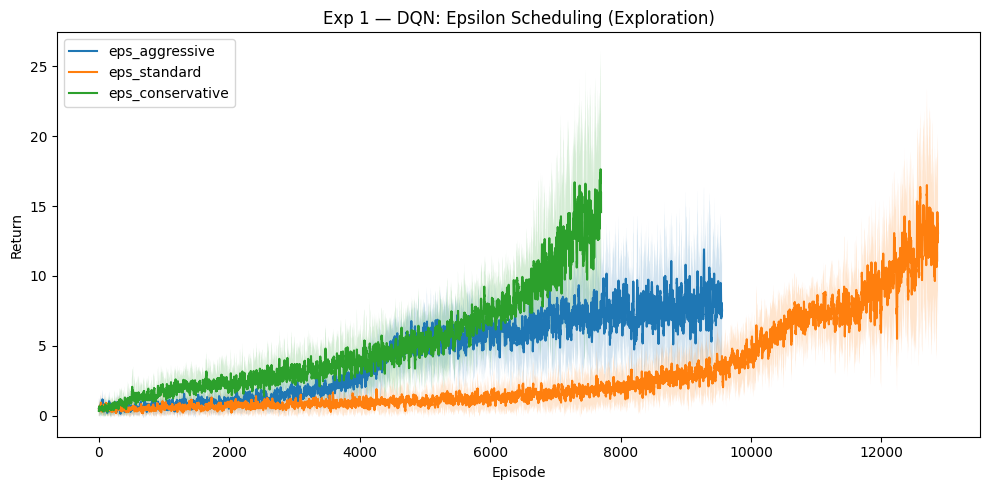


 Exp 1: DQN Epsilon Scheduling
  eps_aggressive               6.40 +/- 1.45
  eps_standard                 12.88 +/- 2.33
  eps_conservative             17.52 +/- 2.70


In [6]:
# Exp 1 — DQN Epsilon Scheduling (Exploration)
# Question: how does the aggressiveness of epsilon-greedy exploration affect learning speed and final performance?
#
# eps_aggressive   : eps_end=0.1  — high exploration throughout
# eps_standard     : eps_end=0.01 — standard decay
# eps_conservative : eps_start=0.5 — less random exploration initially
 
epsilon_variants = [
    {"label": "eps_aggressive",   "eps_start": 1.0, "eps_end": 0.1,
     "eps_decay_steps": 100_000},
    {"label": "eps_standard",     "eps_start": 1.0, "eps_end": 0.01,
     "eps_decay_steps": 250_000},
    {"label": "eps_conservative", "eps_start": 0.5, "eps_end": 0.01,
     "eps_decay_steps": 250_000},
]
 
exp1 = {}
for v in epsilon_variants:
    label = v["label"]
    exp1[label] = []
    for seed in SEEDS:
        cached = load_run("exp1", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp1 | {label} | seed={seed} — already completed")
            exp1[label].append(cached)
            continue
        cfg = {
            "game": GAME, "seed": seed, "total_steps": TOTAL_STEPS,
            "batch_size": 32, "buffer_size": 100_000,
            "lr": 1e-4, "gamma": 0.99, "target_update_freq": 1000,
            "snapshot_steps": SNAPSHOT_STEPS,
            "eps_start": v["eps_start"], "eps_end": v["eps_end"],
            "eps_decay_steps": v["eps_decay_steps"],
        }
        print(f"\n[Exp1] {label} | seed={seed}")
        rets, _ = train_dqn(cfg, run_name=f"dqn_{label}_s{seed}", use_wandb=True)
        exp1[label].append(rets)
        save_run("exp1", label, seed, rets)
 
plot_returns_with_std(exp1, title="Exp 1 — DQN: Epsilon Scheduling (Exploration)")
summarise_results(exp1, "Exp 1: DQN Epsilon Scheduling")


[Exp2] no_buffer | seed=0


Step  10,000 | Episodes:  862 | Avg return (last 20): 0.50 | Eps: 0.960
Step  20,000 | Episodes: 1767 | Avg return (last 20): 0.50 | Eps: 0.921
Step  30,000 | Episodes: 2630 | Avg return (last 20): 0.60 | Eps: 0.881
Step  40,000 | Episodes: 3519 | Avg return (last 20): 0.30 | Eps: 0.842
Step  50,000 | Episodes: 4452 | Avg return (last 20): 0.65 | Eps: 0.802
Step  60,000 | Episodes: 5351 | Avg return (last 20): 0.85 | Eps: 0.762
Step  70,000 | Episodes: 6247 | Avg return (last 20): 0.35 | Eps: 0.723
Step  80,000 | Episodes: 7166 | Avg return (last 20): 0.35 | Eps: 0.683
Step  90,000 | Episodes: 8082 | Avg return (last 20): 0.25 | Eps: 0.644
Step 100,000 | Episodes: 9019 | Avg return (last 20): 0.60 | Eps: 0.604
Step 110,000 | Episodes: 9909 | Avg return (last 20): 0.35 | Eps: 0.564
Step 120,000 | Episodes: 10802 | Avg return (last 20): 0.40 | Eps: 0.525
Step 130,000 | Episodes: 11709 | Avg return (last 20): 0.35 | Eps: 0.485
Step 140,000 | Episodes: 12633 | Avg return (last 20): 0.45 | 

buffer_size,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▁▂▂▂▂▂▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇████████
episode_return,▁▅▅▁█▁▁▁▁▁▅▁▁▁▅▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epsilon,█▇▇▇▇▅▄▄▄▄▃▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇██
buffer_size,1
episode,63134
episode_return,0
epsilon,0.01
loss,0


  [SAVED] /kaggle/working/results/exp2_no_buffer_s0.json

[Exp2] no_buffer | seed=1


Step  10,000 | Episodes:  921 | Avg return (last 20): 0.35 | Eps: 0.960
Step  20,000 | Episodes: 1848 | Avg return (last 20): 0.35 | Eps: 0.921
Step  30,000 | Episodes: 2787 | Avg return (last 20): 0.35 | Eps: 0.881
Step  40,000 | Episodes: 3813 | Avg return (last 20): 0.35 | Eps: 0.842
Step  50,000 | Episodes: 4843 | Avg return (last 20): 0.15 | Eps: 0.802
Step  60,000 | Episodes: 5888 | Avg return (last 20): 0.25 | Eps: 0.762
Step  70,000 | Episodes: 6979 | Avg return (last 20): 0.25 | Eps: 0.723
Step  80,000 | Episodes: 8122 | Avg return (last 20): 0.20 | Eps: 0.683
Step  90,000 | Episodes: 9280 | Avg return (last 20): 0.10 | Eps: 0.644
Step 100,000 | Episodes: 10440 | Avg return (last 20): 0.30 | Eps: 0.604
Step 110,000 | Episodes: 11611 | Avg return (last 20): 0.45 | Eps: 0.564
Step 120,000 | Episodes: 12838 | Avg return (last 20): 0.25 | Eps: 0.525
Step 130,000 | Episodes: 14082 | Avg return (last 20): 0.10 | Eps: 0.485
Step 140,000 | Episodes: 15363 | Avg return (last 20): 0.15 

buffer_size,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇████
episode_return,▁███▁▁█▁▁█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epsilon,█▇▇▆▆▄▄▄▃▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▇▇▇▇▇▇▇▇▇▇████
buffer_size,1
episode,72734
episode_return,0
epsilon,0.01
loss,0


  [SAVED] /kaggle/working/results/exp2_no_buffer_s1.json

[Exp2] no_buffer | seed=2


Step  10,000 | Episodes:  924 | Avg return (last 20): 0.25 | Eps: 0.960
Step  20,000 | Episodes: 1777 | Avg return (last 20): 0.55 | Eps: 0.921
Step  30,000 | Episodes: 2686 | Avg return (last 20): 0.85 | Eps: 0.881
Step  40,000 | Episodes: 3579 | Avg return (last 20): 0.30 | Eps: 0.842
Step  50,000 | Episodes: 4467 | Avg return (last 20): 0.35 | Eps: 0.802
Step  60,000 | Episodes: 5339 | Avg return (last 20): 0.90 | Eps: 0.762
Step  70,000 | Episodes: 6222 | Avg return (last 20): 0.55 | Eps: 0.723
Step  80,000 | Episodes: 7054 | Avg return (last 20): 0.50 | Eps: 0.683
Step  90,000 | Episodes: 7913 | Avg return (last 20): 0.65 | Eps: 0.644
Step 100,000 | Episodes: 8763 | Avg return (last 20): 0.40 | Eps: 0.604
Step 110,000 | Episodes: 9592 | Avg return (last 20): 0.65 | Eps: 0.564
Step 120,000 | Episodes: 10420 | Avg return (last 20): 0.45 | Eps: 0.525
Step 130,000 | Episodes: 11249 | Avg return (last 20): 0.30 | Eps: 0.485
Step 140,000 | Episodes: 12060 | Avg return (last 20): 0.55 | 

buffer_size,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▁▁▁▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▇▇▇▇▇▇▇▇██
episode_return,█▁▃▃▁▁▃▃▃▁▁▁▃▃▁█▃▆▃▁▃▁▁▃▃▁▁▁▃▃▃▃▁▃▃▁▃▃▃▁
epsilon,████▇▇▇▇▆▅▄▄▄▄▃▃▃▃▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇██
buffer_size,1
episode,43794
episode_return,1
epsilon,0.01
loss,0


  [SAVED] /kaggle/working/results/exp2_no_buffer_s2.json

[Exp2] small_buffer | seed=0


Step  10,000 | Episodes:  889 | Avg return (last 20): 0.40 | Eps: 0.960
Step  20,000 | Episodes: 1717 | Avg return (last 20): 0.35 | Eps: 0.921
Step  30,000 | Episodes: 2524 | Avg return (last 20): 0.60 | Eps: 0.881
Step  40,000 | Episodes: 3239 | Avg return (last 20): 0.65 | Eps: 0.842
Step  50,000 | Episodes: 3929 | Avg return (last 20): 0.65 | Eps: 0.802
Step  60,000 | Episodes: 4531 | Avg return (last 20): 1.00 | Eps: 0.762
Step  70,000 | Episodes: 5145 | Avg return (last 20): 1.35 | Eps: 0.723
Step  80,000 | Episodes: 5692 | Avg return (last 20): 1.10 | Eps: 0.683
Step  90,000 | Episodes: 6234 | Avg return (last 20): 0.65 | Eps: 0.644
Step 100,000 | Episodes: 6753 | Avg return (last 20): 0.60 | Eps: 0.604
Step 110,000 | Episodes: 7257 | Avg return (last 20): 1.60 | Eps: 0.564
Step 120,000 | Episodes: 7728 | Avg return (last 20): 1.30 | Eps: 0.525
Step 130,000 | Episodes: 8155 | Avg return (last 20): 1.75 | Eps: 0.485
Step 140,000 | Episodes: 8514 | Avg return (last 20): 2.80 | Eps

buffer_size,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇█████
episode_return,▃▂▁▂▁▂▁▁▂▁▁▂▁▁▁▃▂▁▂▁▁▂▁▃▂▄▁▁▂▄▇▇▅▆▅▂▂▃██
epsilon,██████▇▇▇▇▇▇▇▇▇▇▇▇▆▆▅▅▅▅▅▄▄▄▄▃▂▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▄▂▂▂▂▁▂▁▃▂▂▁▂▂▂▃▂▂▂▂▂▂█▁▁▂▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▆▇▇██
buffer_size,1000
episode,14128
episode_return,13
epsilon,0.01
loss,0.00733


  [SAVED] /kaggle/working/results/exp2_small_buffer_s0.json

[Exp2] small_buffer | seed=1


Step  10,000 | Episodes:  869 | Avg return (last 20): 0.65 | Eps: 0.960
Step  20,000 | Episodes: 1688 | Avg return (last 20): 0.65 | Eps: 0.921
Step  30,000 | Episodes: 2479 | Avg return (last 20): 0.60 | Eps: 0.881
Step  40,000 | Episodes: 3194 | Avg return (last 20): 0.75 | Eps: 0.842
Step  50,000 | Episodes: 3862 | Avg return (last 20): 0.60 | Eps: 0.802
Step  60,000 | Episodes: 4529 | Avg return (last 20): 0.95 | Eps: 0.762
Step  70,000 | Episodes: 5126 | Avg return (last 20): 0.85 | Eps: 0.723
Step  80,000 | Episodes: 5673 | Avg return (last 20): 1.25 | Eps: 0.683
Step  90,000 | Episodes: 6213 | Avg return (last 20): 1.45 | Eps: 0.644
Step 100,000 | Episodes: 6727 | Avg return (last 20): 1.60 | Eps: 0.604
Step 110,000 | Episodes: 7224 | Avg return (last 20): 1.65 | Eps: 0.564
Step 120,000 | Episodes: 7684 | Avg return (last 20): 1.40 | Eps: 0.525
Step 130,000 | Episodes: 8122 | Avg return (last 20): 1.85 | Eps: 0.485
Step 140,000 | Episodes: 8520 | Avg return (last 20): 2.15 | Eps

buffer_size,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇███
episode_return,▁▁▂▁▁▂▂▄▂▁▂▁▂▂▁▁▅▂▂▂▄▂▂▃▄▂▅▆▆▇▇▆▇▆▆▇▃▅██
epsilon,████▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▄▄▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▄█▁▂▃▂▂▂▂▆▂▂▇▂▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▇▇█
buffer_size,1000
episode,14105
episode_return,2
epsilon,0.01
loss,0.01951


  [SAVED] /kaggle/working/results/exp2_small_buffer_s1.json

[Exp2] small_buffer | seed=2


Step  10,000 | Episodes:  880 | Avg return (last 20): 0.70 | Eps: 0.960
Step  20,000 | Episodes: 1735 | Avg return (last 20): 0.65 | Eps: 0.921
Step  30,000 | Episodes: 2495 | Avg return (last 20): 0.55 | Eps: 0.881
Step  40,000 | Episodes: 3235 | Avg return (last 20): 0.55 | Eps: 0.842
Step  50,000 | Episodes: 3953 | Avg return (last 20): 0.80 | Eps: 0.802
Step  60,000 | Episodes: 4587 | Avg return (last 20): 1.05 | Eps: 0.762
Step  70,000 | Episodes: 5224 | Avg return (last 20): 1.35 | Eps: 0.723
Step  80,000 | Episodes: 5799 | Avg return (last 20): 0.85 | Eps: 0.683
Step  90,000 | Episodes: 6350 | Avg return (last 20): 0.60 | Eps: 0.644
Step 100,000 | Episodes: 6890 | Avg return (last 20): 1.45 | Eps: 0.604
Step 110,000 | Episodes: 7379 | Avg return (last 20): 1.15 | Eps: 0.564
Step 120,000 | Episodes: 7828 | Avg return (last 20): 1.25 | Eps: 0.525
Step 130,000 | Episodes: 8262 | Avg return (last 20): 1.50 | Eps: 0.485
Step 140,000 | Episodes: 8622 | Avg return (last 20): 1.50 | Eps

buffer_size,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
episode,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▆▆▆▇▇▇▇▇▇███
episode_return,▁▂▁▂▁▂▁▂▁▁▂▂▁▁▂▁▂▁▂▁▂▁▂▂▂▂▂▂▂▄▃▁▅▃▃▆▅▆▇█
epsilon,█████████▇▇▇▆▆▆▆▅▅▅▅▅▄▄▄▄▄▄▃▃▃▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▃▁▂▁▂█▆▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▅▅▅▆▆▆▆▆▇▇▇▇█
buffer_size,1000
episode,14034
episode_return,13
epsilon,0.01
loss,0.07644


  [SAVED] /kaggle/working/results/exp2_small_buffer_s2.json

[Exp2] standard_buffer | seed=0


Step  10,000 | Episodes:  870 | Avg return (last 20): 0.45 | Eps: 0.960
Step  20,000 | Episodes: 1690 | Avg return (last 20): 0.40 | Eps: 0.921
Step  30,000 | Episodes: 2418 | Avg return (last 20): 0.55 | Eps: 0.881
Step  40,000 | Episodes: 3139 | Avg return (last 20): 1.10 | Eps: 0.842
Step  50,000 | Episodes: 3764 | Avg return (last 20): 1.15 | Eps: 0.802
Step  60,000 | Episodes: 4384 | Avg return (last 20): 1.15 | Eps: 0.762
Step  70,000 | Episodes: 4970 | Avg return (last 20): 1.10 | Eps: 0.723
Step  80,000 | Episodes: 5487 | Avg return (last 20): 1.30 | Eps: 0.683
Step  90,000 | Episodes: 6005 | Avg return (last 20): 1.15 | Eps: 0.644
Step 100,000 | Episodes: 6498 | Avg return (last 20): 1.95 | Eps: 0.604
Step 110,000 | Episodes: 6944 | Avg return (last 20): 1.05 | Eps: 0.564
Step 120,000 | Episodes: 7377 | Avg return (last 20): 2.00 | Eps: 0.525
Step 130,000 | Episodes: 7764 | Avg return (last 20): 1.45 | Eps: 0.485
Step 140,000 | Episodes: 8139 | Avg return (last 20): 2.35 | Eps

buffer_size,▁▁▂▂▂▂▂▂▂▂▄▄▄▅▅▆▆▆▆▇▇███████████████████
episode,▁▁▁▂▂▂▂▂▂▂▂▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇██
episode_return,▁▂▂▁▂▂▃▁▁▁▁▂▁▃▁▁▃▁▂▂▂▁▂▃▂▃▄▆▃▂▃▃▅▄▃▁█▅██
epsilon,███████▇▇▇▇▇▇▇▇▆▆▆▅▅▄▄▄▄▄▃▃▂▂▂▂▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▂▁▁▁▁▁▂▁▁▁▁▁▁▄▃█▁▂▂▆▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▅▆▆▆▆▆█
buffer_size,100000
episode,12988
episode_return,1
epsilon,0.01
loss,0.10269


  [SAVED] /kaggle/working/results/exp2_standard_buffer_s0.json

[Exp2] standard_buffer | seed=1


Step  10,000 | Episodes:  893 | Avg return (last 20): 0.60 | Eps: 0.960
Step  20,000 | Episodes: 1694 | Avg return (last 20): 0.90 | Eps: 0.921
Step  30,000 | Episodes: 2482 | Avg return (last 20): 0.65 | Eps: 0.881
Step  40,000 | Episodes: 3210 | Avg return (last 20): 0.70 | Eps: 0.842
Step  50,000 | Episodes: 3844 | Avg return (last 20): 1.25 | Eps: 0.802
Step  60,000 | Episodes: 4490 | Avg return (last 20): 1.25 | Eps: 0.762
Step  70,000 | Episodes: 5069 | Avg return (last 20): 1.60 | Eps: 0.723
Step  80,000 | Episodes: 5581 | Avg return (last 20): 1.75 | Eps: 0.683
Step  90,000 | Episodes: 6084 | Avg return (last 20): 1.45 | Eps: 0.644
Step 100,000 | Episodes: 6582 | Avg return (last 20): 1.35 | Eps: 0.604
Step 110,000 | Episodes: 7054 | Avg return (last 20): 1.15 | Eps: 0.564
Step 120,000 | Episodes: 7493 | Avg return (last 20): 1.25 | Eps: 0.525
Step 130,000 | Episodes: 7897 | Avg return (last 20): 1.55 | Eps: 0.485
Step 140,000 | Episodes: 8268 | Avg return (last 20): 0.95 | Eps

buffer_size,▁▂▂▂▃▃▃▄▅▅▅▅▅▆▆█████████████████████████
episode,▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇██
episode_return,▁▁▁▁▁▂▂▁▂▁▁▂▁▁▁▁▁▁▃▃▃▁▁▁▃▃▄▄▃▃▂▃▅▁▅▇▅▂▁█
epsilon,█████▇▇▇▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▅▅▅▅▅▅▄▄▄▄▃▃▃▂▂▁▁
loss,▁▁▁▁▁▁▂▁▂▁▁▁▄▁▁▁▅▃▁▁▆▁▁▁▄▁▁█▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▇▇███
buffer_size,100000
episode,12819
episode_return,1
epsilon,0.01
loss,0.1185


  [SAVED] /kaggle/working/results/exp2_standard_buffer_s1.json

[Exp2] standard_buffer | seed=2


Step  10,000 | Episodes:  840 | Avg return (last 20): 0.75 | Eps: 0.960
Step  20,000 | Episodes: 1634 | Avg return (last 20): 0.70 | Eps: 0.921
Step  30,000 | Episodes: 2382 | Avg return (last 20): 0.90 | Eps: 0.881
Step  40,000 | Episodes: 3050 | Avg return (last 20): 1.20 | Eps: 0.842
Step  50,000 | Episodes: 3741 | Avg return (last 20): 0.60 | Eps: 0.802
Step  60,000 | Episodes: 4347 | Avg return (last 20): 1.35 | Eps: 0.762
Step  70,000 | Episodes: 4940 | Avg return (last 20): 1.20 | Eps: 0.723
Step  80,000 | Episodes: 5469 | Avg return (last 20): 1.20 | Eps: 0.683
Step  90,000 | Episodes: 5972 | Avg return (last 20): 1.10 | Eps: 0.644
Step 100,000 | Episodes: 6453 | Avg return (last 20): 1.30 | Eps: 0.604
Step 110,000 | Episodes: 6885 | Avg return (last 20): 1.90 | Eps: 0.564
Step 120,000 | Episodes: 7314 | Avg return (last 20): 1.05 | Eps: 0.525
Step 130,000 | Episodes: 7705 | Avg return (last 20): 1.45 | Eps: 0.485
Step 140,000 | Episodes: 8084 | Avg return (last 20): 2.05 | Eps

buffer_size,▁▁▂▂▂▄▄▄▄▄▄▅▅▅▆▆▇▇▇▇████████████████████
episode,▁▁▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇████
episode_return,▁▁▁▁▁▁▁▁▁▁▁▂▂▁▁▁▂▁▁▁▁▁▂▁▃▂▂▅▁▅▅▅▄▅▅▇▃█▇▇
epsilon,██████▇▇▇▇▆▆▆▆▅▅▅▅▅▅▅▅▄▄▄▄▄▄▄▄▃▃▃▂▂▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▃▃▁▁▃▁▁▁▁▁▁▂▁█▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▆▇▇█
buffer_size,100000
episode,12853
episode_return,8
epsilon,0.01
loss,0.2184


  [SAVED] /kaggle/working/results/exp2_standard_buffer_s2.json


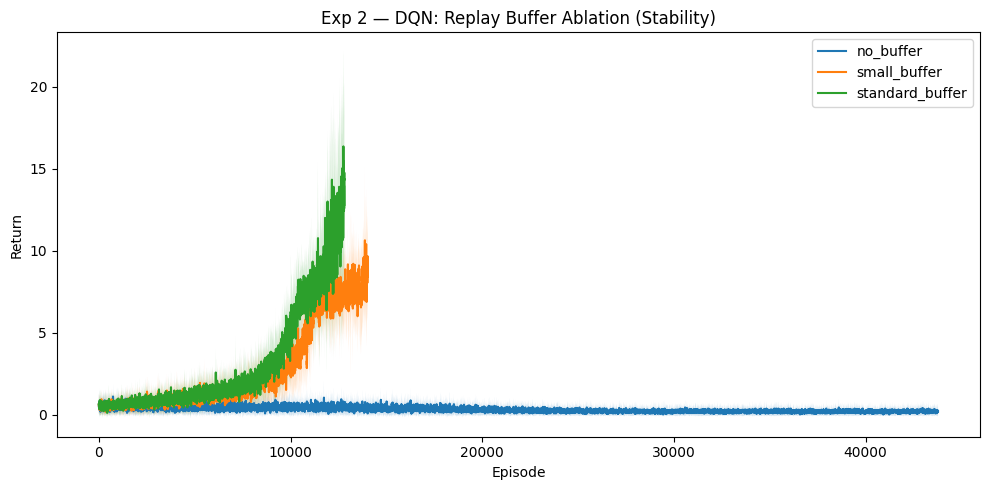


 Exp 2: DQN Replay Buffer Ablation
  no_buffer                    0.22 +/- 0.24
  small_buffer                 8.50 +/- 0.53
  standard_buffer              11.98 +/- 2.33


In [7]:
# Exp 2 — DQN Replay Buffer Ablation (Stability)
# Question: how does replay buffer size affect training stability?
# buffer_size=0 removes replay entirely (on-policy-like ablation).
# Without replay, consecutive samples are highly correlated -> instability.
 
buffer_variants = [
    {"label": "no_buffer",       "buffer_size": 0},
    {"label": "small_buffer",    "buffer_size": 1_000},
    {"label": "standard_buffer", "buffer_size": 100_000},
]
 
exp2 = {}
for v in buffer_variants:
    label = v["label"]
    exp2[label] = []
    for seed in SEEDS:
        cached = load_run("exp2", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp2 | {label} | seed={seed} — already completed")
            exp2[label].append(cached)
            continue
        cfg = {
            "game": GAME, "seed": seed, "total_steps": TOTAL_STEPS,
            "batch_size": 32, "lr": 1e-4, "gamma": 0.99,
            "eps_start": 1.0, "eps_end": 0.01, "eps_decay_steps": 250_000,
            "target_update_freq": 1000, "snapshot_steps": SNAPSHOT_STEPS,
            "buffer_size": v["buffer_size"],
        }
        print(f"\n[Exp2] {label} | seed={seed}")
        rets, _ = train_dqn(cfg, run_name=f"dqn_{label}_s{seed}", use_wandb=True)
        exp2[label].append(rets)
        save_run("exp2", label, seed, rets)
 
plot_returns_with_std(exp2, title="Exp 2 — DQN: Replay Buffer Ablation (Stability)")
summarise_results(exp2, "Exp 2: DQN Replay Buffer Ablation")


[Exp3] no_entropy | seed=0


Step  80,000 | Episodes: 2495 | Avg return (last 20): 3.90
Step 160,000 | Episodes: 3974 | Avg return (last 20): 4.50
Step 240,000 | Episodes: 5297 | Avg return (last 20): 5.55
Step 320,000 | Episodes: 6546 | Avg return (last 20): 5.40
Step 400,000 | Episodes: 7755 | Avg return (last 20): 4.95
Step 480,000 | Episodes: 8981 | Avg return (last 20): 5.95


episode,▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇████
episode_return,▁▂▂▂▃▄▄▅▅▅▇▇▆▆▇▇▇▇█▇▇▇▇▆▇▇▇█▇▇█▇█▇▇███▇█
policy_entropy,█▅▄▃▆▅▄█▇▆▆▆▅█▅▃▃▃▅▁▄▅▂▂▄▅▄▅▃▄▅▅▅▄▃▃▄▃▁▅
policy_loss,█▃▇▃▂▆▅▆▁▅▄▅▆▁▃▆▃▇▃▃▆▅▅▅▅▅▆▄▃▅▂▃▅▃▂▆▂▇▆▄
step,▁▁▁▁▂▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▄▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇████
total_loss,▂▃▇▂▂▁▁▂▂▂▂▂▁▂▂▂▆▅▃▁▁▂▂█▂▁▁▄▆▂▃▂▂▁▁▁▁▂▄▁
value_loss,▅▂▂█▅▄▃▂▁▂▂▂▁▁▁▁▇▃▂▁▄▁▁▁▃▁▂▅▂▄▃▁▁▁▃▁▁▇▄▂
episode,9283
episode_return,5.85
policy_entropy,0.66124
policy_loss,-0.02631


  [SAVED] /kaggle/working/results/exp3_no_entropy_s0.json

[Exp3] no_entropy | seed=1


Step  80,000 | Episodes: 4106 | Avg return (last 20): 1.55
Step 160,000 | Episodes: 7825 | Avg return (last 20): 2.70
Step 240,000 | Episodes: 9494 | Avg return (last 20): 4.75
Step 320,000 | Episodes: 10910 | Avg return (last 20): 4.25
Step 400,000 | Episodes: 12280 | Avg return (last 20): 4.75
Step 480,000 | Episodes: 13635 | Avg return (last 20): 5.00


episode,▁▁▁▁▁▂▃▃▃▃▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇████
episode_return,▁▂▂▂▂▂▂▂▂▂▂▂▂▄▄▆▆▆▅▇▆▇▆▇▆▇█▇▇▇▇█▇██▆▆▇██
policy_entropy,▅▁▄█▁▄▅▆▄▅▆▆▄▅▆▅▄▅▆▅▄▆▆██▇▇▇▅▄▅▄▆▇▆▅▆▆▄▅
policy_loss,▅▅▅▃▇▁█▃▅▅▁▄▄▄▅▃▁▄▅▅▄▅▄▂▃▃▃▄▂▂▃▄▃▃▄▃▅▃▃▄
step,▁▁▁▁▁▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇█
total_loss,▃▂▂▂▂▂▂▂▂▁▃▅▃▅▅▄▃▄▃▂▂▃▂▂▁▂▄▂▂█▆▂▂▂▃▃▂▃▂▃
value_loss,▁▁▁▁▁▁▁▁▂▁█▄▃▃▂▇▁▂▃▄▂▃▃▁▄▁▁█▁▁▃▁▃▁▁▅▂▂▃▂
episode,13963
episode_return,5.15
policy_entropy,0.65015
policy_loss,-0.03017


  [SAVED] /kaggle/working/results/exp3_no_entropy_s1.json

[Exp3] no_entropy | seed=2


Step  80,000 | Episodes: 2462 | Avg return (last 20): 4.50
Step 160,000 | Episodes: 3869 | Avg return (last 20): 5.10
Step 240,000 | Episodes: 5162 | Avg return (last 20): 5.05
Step 320,000 | Episodes: 6417 | Avg return (last 20): 5.50
Step 400,000 | Episodes: 7621 | Avg return (last 20): 5.80
Step 480,000 | Episodes: 8820 | Avg return (last 20): 4.80


episode,▁▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇██
episode_return,▁▂▅▄▄▄▅▅▆▆▆▇▇▇▅▇▆▇▇▆▇▆█▆▆▇▇▇▇██▆████▆▇█▇
policy_entropy,█▇▆▅▆▁▂▂▄▆▂▆▅▄▄▆▆▆▅▄▅▅▃▅▄▃▂▃▂▄▃▁▃▃▂▂▂▂▂▂
policy_loss,█▂▆▇▃▄▆▆▆█▄▄▄▅▆▄▄▅▆▄▄▅▄▂▄▅▅▂▄▄▃▃▅▂▄▃▁▅▄▄
step,▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇████
total_loss,▄▃▅▂▂▅▁▃▁▁▂▁▂▁▄▂▂▂▂▁█▁▃▆▂▅▄█▃▁▁▁▄▄▁▂▁▄▂▂
value_loss,▂▃▃▃▂▂▃▁▁▁▂▁▂▂▃▃▁▁▁▁▁█▂▃▁▁▁▁▅▄▁▃▁▁▁▁▁▁▆▂
episode,9117
episode_return,5.7
policy_entropy,0.5998
policy_loss,-0.03244


  [SAVED] /kaggle/working/results/exp3_no_entropy_s2.json

[Exp3] low_entropy | seed=0


Step  80,000 | Episodes: 2471 | Avg return (last 20): 4.25
Step 160,000 | Episodes: 3872 | Avg return (last 20): 5.05
Step 240,000 | Episodes: 5161 | Avg return (last 20): 5.45
Step 320,000 | Episodes: 6364 | Avg return (last 20): 6.05
Step 400,000 | Episodes: 7626 | Avg return (last 20): 5.90
Step 480,000 | Episodes: 8818 | Avg return (last 20): 5.75


episode,▁▁▁▂▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇██████
episode_return,▁▁▂▃▄▆▆▆▆▅▆▆▆▇▇▇▇▆▇▆▇▇▇▇▇▇▇█▆▆▇▇██▇▇▇▆█▇
policy_entropy,█▇▆▇▂▃▁▃▅▄▂▃▄▃▃▄▄▃▅▄▃▃▂▂▁▂▁▂▃▃▂▃▂▃▃▄▃▃▂▂
policy_loss,▆▇▅▇▄▇▇▅█▇█▆▅▂▇▇▄▂▅▁▇▃▄▁▁▄▅▂▁▆▂▃▅▅▆▄█▆▆▃
step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▇█████
total_loss,▅▃▄▃▄▃▇▂▃▂▂▂▂▂▂▂▂▂▂▂▂▂▃▂▇▂▂▁▁▃▁▁▁▄▁█▂▂▂▁
value_loss,▂▂▂▁▃▁▁▁▁▁▁▁▁▂▁▁▁▁▁▂▁▁▁▂▂▄▃▂▂▁▁▁▁▃▁▁▁▁█▁
episode,9126
episode_return,5.7
policy_entropy,0.64596
policy_loss,-0.05926


  [SAVED] /kaggle/working/results/exp3_low_entropy_s0.json

[Exp3] low_entropy | seed=1


Step  80,000 | Episodes: 3287 | Avg return (last 20): 2.90
Step 160,000 | Episodes: 4885 | Avg return (last 20): 5.35
Step 240,000 | Episodes: 6270 | Avg return (last 20): 5.45
Step 320,000 | Episodes: 7509 | Avg return (last 20): 5.50
Step 400,000 | Episodes: 8705 | Avg return (last 20): 6.30
Step 480,000 | Episodes: 9858 | Avg return (last 20): 5.65


episode,▁▂▂▂▂▃▃▃▄▄▄▄▄▄▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇█████
episode_return,▁▁▂▂▄▄▄▅▄▄▅▅▆▆▆▆▆▆▆▆▅▆▇▇▆▆▇▇▇▇▇▇▇▇▇▆█▇█▆
policy_entropy,▅▂▁▅▅▇█▆▆▇▆▆▇▆▆▅▆▅▅▅▇▅▆▆▅▄▃▄▂▄▃▄▅▄▅▅▆▅▄▄
policy_loss,▆▇▅▄▄▄▄▇▆▆▆▁█▅▆▅▄▄▆▃▆▆▇▃▅▃▆▇▆▆▇▃▇▅▆▆▄▇▆▄
step,▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇██
total_loss,▄▃▂▃▄█▂▄▅▃▄▄▃▃▃▂▂▅▄▃▂▂▂▁▅▂▂▂▂▂▃▂▂▃▂▃▂▂▅▂
value_loss,▁▁▁▃▃▂█▂▁▇▁▂▄▁▅▂▁▁▂▁▁▃▁▁▁▁▁▂▁▃▁▆▅▁▃▇▁▁▄▁
episode,10157
episode_return,6.15
policy_entropy,0.39585
policy_loss,-0.01037


  [SAVED] /kaggle/working/results/exp3_low_entropy_s1.json

[Exp3] low_entropy | seed=2


Step  80,000 | Episodes: 2489 | Avg return (last 20): 5.05
Step 160,000 | Episodes: 3866 | Avg return (last 20): 5.60
Step 240,000 | Episodes: 5074 | Avg return (last 20): 6.10
Step 320,000 | Episodes: 6305 | Avg return (last 20): 4.05
Step 400,000 | Episodes: 7603 | Avg return (last 20): 4.60
Step 480,000 | Episodes: 8882 | Avg return (last 20): 5.70


episode,▁▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇█████
episode_return,▁▃▅▅▆▆▇▅▇▆▇▆▇▇▇▇▇▇▇█▇██▆▇▇███▇▇█▆▆▇█▇▆▇▇
policy_entropy,▇█▇▇▅▄▅▂▂▂▃▃▃▅▅▅▅▃▄▆▂▄▃▁▃▆▅▄▄▄▅▄▅▃▅▂▄▅▃▄
policy_loss,█▁▃▆▅▆▇▇▅▂▆▇▅▄▂▆▅▄▅▂▅▅▆▇▄█▆▃▄▆▆▄▁▅▇▅▃▃▄▆
step,▁▁▁▁▁▁▂▂▂▂▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇██
total_loss,▄▃▆▅▃▂▁▂▂▂▃▂▂▃▂▂▁▂▂▃▁▁▇▂▂▂▂▃▅▂█▂▁▁▂▂▇▃▁▆
value_loss,▃▂▂▁▁▁▁▁▂▁▁▁▂▁▄▂▂▁▁▄▁▁▃▁▁▃▁▁▁▁▁▄▄▁▂▁▁█▄▁
episode,9201
episode_return,5.25
policy_entropy,0.55213
policy_loss,-0.02455


  [SAVED] /kaggle/working/results/exp3_low_entropy_s2.json

[Exp3] std_entropy | seed=0


Step  80,000 | Episodes: 2469 | Avg return (last 20): 3.85
Step 160,000 | Episodes: 3901 | Avg return (last 20): 5.40
Step 240,000 | Episodes: 5177 | Avg return (last 20): 5.40
Step 320,000 | Episodes: 6424 | Avg return (last 20): 5.85
Step 400,000 | Episodes: 7489 | Avg return (last 20): 7.65
Step 480,000 | Episodes: 8374 | Avg return (last 20): 8.10


episode,▁▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇█████
episode_return,▁▂▃▃▃▄▄▅▄▄▅▄▅▅▅▆▆▅▅▅▅▅▅▄▆▆▅▆▆▅▇▆▇▇█▇████
policy_entropy,▅▄█▇▅▆▄▆██▇▄▄▆▇▆▄▆█▆▆▄▄▆▃▃▄▄▇▆▃▄▃▅▄▆▅▁▃▄
policy_loss,▇▇█▆▅▃▅▄▂█▅▆▄▆▅▆▃▃▅█▅▂▄▃▄▃▂▅▂▆▃▄▂▃▁▄▅▅▇▄
step,▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
total_loss,▂▂▁▂▂▂▁▁▂▁▁▁▁▁▂▂▂▁▂▁▂▁▁▁▁▁▁▁▁▁▃█▂▁▂▁▃▂▁▄
value_loss,▁▂▂▂▄▁▂▁▁▂▁▂▂▂▁▁▁▁▁▁▂▃▁▁▁▁▁▁▁█▂▁▅▁█▁▁▁▃▃
episode,8583
episode_return,8.05
policy_entropy,0.72212
policy_loss,-0.03573


  [SAVED] /kaggle/working/results/exp3_std_entropy_s0.json

[Exp3] std_entropy | seed=1


Step  80,000 | Episodes: 2859 | Avg return (last 20): 3.40
Step 160,000 | Episodes: 4365 | Avg return (last 20): 4.35
Step 240,000 | Episodes: 5798 | Avg return (last 20): 4.45
Step 320,000 | Episodes: 7177 | Avg return (last 20): 4.70
Step 400,000 | Episodes: 8432 | Avg return (last 20): 5.40
Step 480,000 | Episodes: 9648 | Avg return (last 20): 5.15


episode,▁▃▃▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇████
episode_return,▁▁▂▂▂▄▄▅▅▅▅▇▆▅▇▆▇▆▅▇▆▆▇▇▇▆▆▇█▇▇▇▆▇█▆▇▆██
policy_entropy,▁▅▆▁▇▇█▆█▇▃▆▆▄▅▆▇▆▅▆▅▆▅▇▆▄▅▅▄▃▃▅▆▃▃▃▃▄▅▅
policy_loss,▆▅▇▅▇▅▄▆▅▆▅▆▆▆▃▅▆█▃▄▅▆▆▃▅▅▆▃▄▄▇▅▅▆▄▆▆▁▄▆
step,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇█
total_loss,▄▂▆▅▃▃▃▂▄▃▅▆▃▂▂▂▂▄▂▃▄▂█▂▂▂▂▅▂▂▂▂▂▃▂▂▂▁▂▂
value_loss,▂▄▂▄▆▃▁▁▂▁▆▁▁▁▄▂▁▁▁▃▃▁▁▄▅▁▁▁▁▁▃▁▇▄▁█▁▆▁▁
episode,9950
episode_return,6.05
policy_entropy,0.6066
policy_loss,-0.00088


  [SAVED] /kaggle/working/results/exp3_std_entropy_s1.json

[Exp3] std_entropy | seed=2


Step  80,000 | Episodes: 2494 | Avg return (last 20): 3.55
Step 160,000 | Episodes: 3929 | Avg return (last 20): 5.30
Step 240,000 | Episodes: 5147 | Avg return (last 20): 6.00
Step 320,000 | Episodes: 6334 | Avg return (last 20): 5.95
Step 400,000 | Episodes: 7496 | Avg return (last 20): 6.75
Step 480,000 | Episodes: 8424 | Avg return (last 20): 7.45


episode,▁▁▁▁▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▆▆▆▇▇▇▇▇▇▇▇██████
episode_return,▁▂▂▄▃▄▄▄▄▄▅▅▅▄▅▆▅▆▆▆▅▅▆▆▆▆▆▆▆▆▆▅▆▆▆▆█▇▇▇
policy_entropy,█▆▆▃▅▄▃▅▅▄▅▄▄▄▄▂▄▃▄▂▄▃▂▁▃▂▂▂▂▁▃▂▁▂▂▃▁▁▁▂
policy_loss,▇█▃▆▁▅██▆▆▂▆▅▁▄▃▃▄▁▄▅▄▆▅▂▆▁▅▅▃▅▃▆▄▃▅▆▅▃▆
step,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▇▇▇▇▇▇▇▇█
total_loss,▂▂▂▂▃▃▂▂▁▂▁▂▁▁▁▂▁▁▁▁▁▂▃▁▁▇▁▂▂▁▁▂▁▁▂█▁▁▁▇
value_loss,▅▄▄▅▂▁▁▇▁▁▁▁▂▄▁▁▁█▁▁▁▄▁▁▅▁▁▁▃▁▃▁▃█▃▂▃▁▂▁
episode,8640
episode_return,9.15
policy_entropy,0.41024
policy_loss,-0.01691


  [SAVED] /kaggle/working/results/exp3_std_entropy_s2.json

[Exp3] high_entropy | seed=0


Step  80,000 | Episodes: 2698 | Avg return (last 20): 3.70
Step 160,000 | Episodes: 4203 | Avg return (last 20): 6.30
Step 240,000 | Episodes: 5273 | Avg return (last 20): 7.25
Step 320,000 | Episodes: 6241 | Avg return (last 20): 8.40
Step 400,000 | Episodes: 7086 | Avg return (last 20): 10.20
Step 480,000 | Episodes: 7845 | Avg return (last 20): 12.90


episode,▁▁▁▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇███
episode_return,▁▁▁▂▂▃▂▂▃▃▂▃▃▃▃▄▅▄▃▄▅▅▆▅▅▅▆▅▆▆▇▇▇▇▇█▄▇▆▇
policy_entropy,██▆▇▆▇▆▆▇▆▄▅▃▃▅▅▄▂▃▄▆▅▄▄▄▄▄▄▄▄▁▄▆▂▃▄▅▃▃▄
policy_loss,▇▆▇▆▆▄▆▅▆▃▆▇▆▆▅▇▅▇▆▇▅▄▄▆▃▆▅▆▄▇▅▅▄▅▅▆▁█▂▆
step,▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
total_loss,▁▃▂▂▂▁▂▂▂▁▁▁▂▂▁▁▁▂▁▂▁▁▂▁▁█▁▂▁▃▄▁▂▁▅▂▂▁▁▂
value_loss,▁▁▂▁▂▁▁▁▁▁▁▂▁▁▃▁▁▁▁▂▁▁▂▁▁▁█▂▁▂▄▂▂▁▁▁▁▁▁▁
episode,8032
episode_return,10.15
policy_entropy,1.22665
policy_loss,-0.03414


  [SAVED] /kaggle/working/results/exp3_high_entropy_s0.json

[Exp3] high_entropy | seed=1


Step  80,000 | Episodes: 2714 | Avg return (last 20): 3.75
Step 160,000 | Episodes: 4199 | Avg return (last 20): 4.80
Step 240,000 | Episodes: 5365 | Avg return (last 20): 6.65
Step 320,000 | Episodes: 6299 | Avg return (last 20): 7.95
Step 400,000 | Episodes: 7127 | Avg return (last 20): 8.30
Step 480,000 | Episodes: 7967 | Avg return (last 20): 8.80


episode,▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇█
episode_return,▁▁▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▄▄▄▅▅▅▆▆▆▅▆▆▅▅▇▇▆█▆▇███
policy_entropy,▇█▆▆▅▃▅▅▄▅▅▄▆▆▂▄▃▄▃▄▄▃▅▄▄▅▄▄▁▁▃▄▃▆▅▃▅▂▅▃
policy_loss,▅▅▇▃▃█▅▆▅▄▆▆▃▃▅▂▅▅▅▆▆▃▁▄▃▃▃▁▅▂█▂▄▄▅▂▆▆▄▇
step,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇███
total_loss,▃▄▂▂▂▄▂▂▃▃▄▂▅▂▂▂▂▂▂▂▁▁▂▁▂▁▆▂▄▁▃▁▁▂▃▁▁█▅▂
value_loss,▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁█▁▁▂▁▁▁▂▁▂▁▁▂▁▁▁▁▃
episode,8167
episode_return,9.15
policy_entropy,1.29291
policy_loss,-0.02911


  [SAVED] /kaggle/working/results/exp3_high_entropy_s1.json

[Exp3] high_entropy | seed=2


Step  80,000 | Episodes: 2564 | Avg return (last 20): 4.10
Step 160,000 | Episodes: 3966 | Avg return (last 20): 5.35
Step 240,000 | Episodes: 5066 | Avg return (last 20): 7.60
Step 320,000 | Episodes: 5973 | Avg return (last 20): 9.45
Step 400,000 | Episodes: 6788 | Avg return (last 20): 10.65
Step 480,000 | Episodes: 7593 | Avg return (last 20): 9.45


episode,▁▁▁▁▁▂▂▂▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇█████
episode_return,▁▂▂▂▃▃▃▃▄▄▄▅▅▄▄▅▆▅▆▅▅█▆▆▆▅▆▆▆▅▆▇▅▅█▇▅▆▆█
policy_entropy,█▇▇█▆▆▃▅▇▆▆▄▅▄▆▃▅▃▄▄▅▃▄▄▃▅▃▃▄▅▂▂▂▁▂▄▃▃▃▃
policy_loss,█▂▇▇▆▄▆▆▁▅▄▅▁▆▅▄▃▅▆▄▅▄▄▅▃▅▂▃▃▄▄▅▆▂▅▁▅▄▄▄
step,▁▁▁▁▁▂▂▂▂▂▂▂▂▂▃▃▃▃▄▄▄▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇███
total_loss,▃▂▂▃▂▂▂▁▃▂▁▁▅▄▁▂▂▁▂▁▃▁▂▆▁▂▆▁▇▂▄▄█▂▂▂█▃▄▂
value_loss,▃▁▁▂▁▃▂▁▂▁▁▁▁▁▃▃▅▂▁▂▃▁▂▂▁▂▁▂▂▂▂▅▃▄█▁▇▂▁▄
episode,7790
episode_return,8.7
policy_entropy,1.23931
policy_loss,-0.04809


  [SAVED] /kaggle/working/results/exp3_high_entropy_s2.json


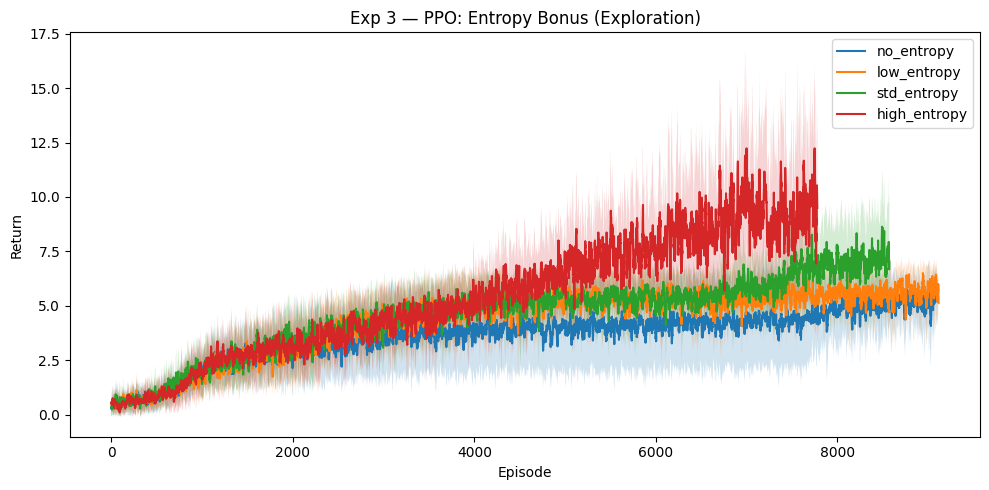


 Exp 3: PPO Entropy Bonus
  no_entropy                   5.57 +/- 0.30
  low_entropy                  5.70 +/- 0.37
  std_entropy                  7.75 +/- 1.28
  high_entropy                 9.33 +/- 0.61


In [8]:
# Exp 3 — PPO Entropy Bonus (Exploration) 
# Question: how does the entropy coefficient affect exploration and performance?
# ent_coef=0.0 removes the entropy bonus entirely.
# High ent_coef encourages the policy to remain uncertain -> more exploration.
 
entropy_variants = [
    {"label": "no_entropy",   "ent_coef": 0.0},
    {"label": "low_entropy",  "ent_coef": 0.001},
    {"label": "std_entropy",  "ent_coef": 0.01},
    {"label": "high_entropy", "ent_coef": 0.05},
]
 
exp3 = {}
for v in entropy_variants:
    label = v["label"]
    exp3[label] = []
    for seed in SEEDS:
        cached = load_run("exp3", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp3 | {label} | seed={seed} — already completed")
            exp3[label].append(cached)
            continue
        cfg = {
            "game": GAME, "seed": seed, "total_steps": TOTAL_STEPS,
            "n_steps": 128, "n_epochs": 4, "batch_size": 32,
            "lr": 2.5e-4, "gamma": 0.99, "gae_lambda": 0.95,
            "clip_coef": 0.2, "vf_coef": 0.5, "max_grad_norm": 0.5,
            "snapshot_steps": SNAPSHOT_STEPS,
            "ent_coef": v["ent_coef"],
        }
        print(f"\n[Exp3] {label} | seed={seed}")
        rets, _ = train_ppo(cfg, run_name=f"ppo_{label}_s{seed}", use_wandb=True)
        exp3[label].append(rets)
        save_run("exp3", label, seed, rets)
 
plot_returns_with_std(exp3, title="Exp 3 — PPO: Entropy Bonus (Exploration)")
summarise_results(exp3, "Exp 3: PPO Entropy Bonus")


[Exp4] no_clip | seed=0


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Step  80,000 | Episodes: 2669 | Avg return (last 20): 3.75
Step 160,000 | Episodes: 4194 | Avg return (last 20): 4.95
Step 240,000 | Episodes: 5621 | Avg return (last 20): 3.55
Step 320,000 | Episodes: 7009 | Avg return (last 20): 4.90
Step 400,000 | Episodes: 8375 | Avg return (last 20): 4.60
Step 480,000 | Episodes: 9661 | Avg return (last 20): 5.20


episode,▁▁▁▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇███
episode_return,▁▁▂▂▄▃▆▇▆▇▄▇▇▅▆▅▅▄▆▆▆▆▆▁▇▇▆▆▆▆▇▆▃▇▇█▇▅▇█
policy_entropy,█▆▆▅▄▄▅▄▅▄▃▃▃▁▁▃▃▄▄▃▃▂▂▃▄▂▃▃▂▂▃▄▂▂▁▃▃▃▃▂
policy_loss,▇▅▇▇▃▆▃▃█▁▇▅▅█▅█▄▇▅▆▆▆▆▃▅▆▇▂▇▅▆▇▆▇▅▆▃▄▅▄
step,▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇▇██████
total_loss,▆▆██▇▇▆▄▄▄▄█▄▇▅▃▆▁▅▃▆▄▄▃▄▃▃▄▃▄▆▃▄▁▄▂▃▂▃▄
value_loss,▂▃▂▂▂▁▂▄▁▁▆▁▁▄▃▁█▁▁▁▁▁▁▁▂▁▂▄▁▁▁▁▁▃▁▄▁▁▁▁
episode,9958
episode_return,5.65
policy_entropy,0.36729
policy_loss,-0.03597


  [SAVED] /kaggle/working/results/exp4_no_clip_s0.json

[Exp4] no_clip | seed=1


Step  80,000 | Episodes: 2647 | Avg return (last 20): 4.90
Step 160,000 | Episodes: 4115 | Avg return (last 20): 4.95
Step 240,000 | Episodes: 5547 | Avg return (last 20): 4.70
Step 320,000 | Episodes: 6965 | Avg return (last 20): 5.10
Step 400,000 | Episodes: 8314 | Avg return (last 20): 4.65
Step 480,000 | Episodes: 9540 | Avg return (last 20): 6.40


episode,▁▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇█████
episode_return,▂▁▂▃▃▆▅▆▅▅▅▅▅▅▅▆▆▅▅▆▅▆▅▅▅▅▅▆▅▅▆▆▆▆▆▆▆▆▇█
policy_entropy,██▄▆▆▆▄▅▂▃▃▅▃▃▃▂▁▃▂▁▂▄▄▃▄▂▂▂▃▂▂▂▂▃▂▁▃▃▃▃
policy_loss,▆▆▅▇▇▇▆▄▅▂▆▆▆▆▁█▅▇▄▆▇▇▆▆▆▇▇▆▇▇▇▄▃▇▅▆▆▃▄▆
step,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▇▇▇▇▇██
total_loss,▄▄▃▄▅▃▂▃▆▃▂▂▃▂▂▇▅▆▂▃▅▃▂▂▂▁▂▂▂▆█▂▂▂▂▂▃▂▂▂
value_loss,▅▃▃▃▂▃▃▂▁▂▂▁▂▁▄▁█▁▁▇▁█▁▁▁▂▁▁▁▆█▁▁▂▁▁▁▁▃▄
episode,9793
episode_return,6.9
policy_entropy,0.7812
policy_loss,-0.02603


  [SAVED] /kaggle/working/results/exp4_no_clip_s1.json

[Exp4] no_clip | seed=2


Step  80,000 | Episodes: 2748 | Avg return (last 20): 4.00
Step 160,000 | Episodes: 4241 | Avg return (last 20): 6.10
Step 240,000 | Episodes: 5537 | Avg return (last 20): 6.80
Step 320,000 | Episodes: 6538 | Avg return (last 20): 8.60
Step 400,000 | Episodes: 7402 | Avg return (last 20): 9.70
Step 480,000 | Episodes: 8182 | Avg return (last 20): 8.65


episode,▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▅▅▆▆▆▆▆▇▇▇▇▇▇▇████████
episode_return,▁▂▂▂▂▃▃▄▄▃▄▄▄▄▄▄▃▆▅▅▅▅▅▅▆▆▆▇▆▅▆▇▆▆▇▆▆▇▇█
policy_entropy,█▇▆▅▅▅▄▄▁▃▁▁▁▃▂▁▁▂▂▂▂▃▃▂▂▂▃▂▂▃▄▄▃▂▃▂▃▃▃▂
policy_loss,▆█▅▆▆▇▇▄█▄▆▇▇▂▆▆▅▁▇▆▆▆▇▆▇▄▄▆▆▅▅▂▄▅▅▆▆▇▇▆
step,▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇██
total_loss,▃▂▂▁▂▂▂▁▂▃▂▂▁▅▁▄▂▂▆▂▂▂▂▁▃▃▃▇▂▃▂▄▂▃▄▂▂▃█▂
value_loss,▅▁▂▂▁▁▂▅▁▁▃▁▂▁▁▂▁▁▂▃▃▂▁▄▁▂▅▄▆▂▁▁▂█▁▄▃▃▂▂
episode,8367
episode_return,8.3
policy_entropy,0.55735
policy_loss,-0.00256


  [SAVED] /kaggle/working/results/exp4_no_clip_s2.json

[Exp4] tight_clip | seed=0


Step  80,000 | Episodes: 2615 | Avg return (last 20): 3.55
Step 160,000 | Episodes: 4158 | Avg return (last 20): 4.95
Step 240,000 | Episodes: 5354 | Avg return (last 20): 7.50
Step 320,000 | Episodes: 6277 | Avg return (last 20): 7.35
Step 400,000 | Episodes: 7153 | Avg return (last 20): 7.70
Step 480,000 | Episodes: 7994 | Avg return (last 20): 7.70


episode,▁▁▁▁▁▂▂▂▂▂▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇██
episode_return,▁▁▁▁▂▂▂▂▂▃▃▃▃▄▃▃▄▄▅▄▆▅▅▅▅▅▅▆▇▇▇▅▇▆▆▆▆▅▇█
policy_entropy,█▆▆▆▆▇▆▆▆▅▆▆▅▄▅▅▅▅▅▄▂▃▃▄▄▆▃▄▄▃▃▃▂▃▂▂▂▂▁▄
policy_loss,█▅▆█▅▁▅▄█▅▇▄▆▅▂▄▂▃▅▄▄▄▄▅▄▃▇▂▄▃▄▂▃▂▆▇▄▇▅▅
step,▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇███
total_loss,▁▃▁▂▃▂▁▃▄▂▁▂▄▃▂▁▁▁▂▁▁▅▁▁▁▂▂▁▁▁▁▁▁█▁▁▁▂▁▃
value_loss,▁▁▁▁▁▁▂▁▁▂▂▁▁▁▁▂▁▁▁▂▁▁▁▁▁▁▁▂▁▂▁▃▁█▁▁▂▂▃▁
episode,8189
episode_return,8.15
policy_entropy,0.71842
policy_loss,-0.01564


  [SAVED] /kaggle/working/results/exp4_tight_clip_s0.json

[Exp4] tight_clip | seed=1


Step  80,000 | Episodes: 2628 | Avg return (last 20): 4.65
Step 160,000 | Episodes: 4033 | Avg return (last 20): 5.50
Step 240,000 | Episodes: 5374 | Avg return (last 20): 3.70
Step 320,000 | Episodes: 6654 | Avg return (last 20): 5.50
Step 400,000 | Episodes: 7921 | Avg return (last 20): 6.25
Step 480,000 | Episodes: 8929 | Avg return (last 20): 6.40


episode,▁▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇██████
episode_return,▁▁▁▁▃▄▄▄▄▅▅▆▅▅▆▅▆▅▆▆▆▅▅▅▆▆▆▆▆▆▇▆▇████▇▇▇
policy_entropy,▇████▆▆▇▅▆▆▅▃▄▄▃▄▄▃▃▄▄▅▅▅▃▂▄▂▂▃▂▃▂▁▂▂▅▁▂
policy_loss,▄█▄▃▄▄▅▄▃▂▃▃▄▅▄▄▄▃▄▃▄▁▄▄▄▂▂▄▁▄▃▃▃▂▃▄▄▄▃▄
step,▁▁▁▂▂▂▂▂▂▂▂▂▂▂▃▃▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▇████
total_loss,▂▃▆▃▅▄▆▅▃▄▁▁▁▄▁▄▁▁▁▁▁▅▁▇▄▁▁▁▁▂▁▁▂▄▂▄▄█▅▂
value_loss,▃▂▂▃▅▃▂▁▂▂▁▁▂▁▂▁▂▅▂▁▂▁▅▁▃▁▁▇█▂▆▁▁▁▁▁▄▁▃▂
episode,9155
episode_return,8.85
policy_entropy,1.00591
policy_loss,-0.031


  [SAVED] /kaggle/working/results/exp4_tight_clip_s1.json

[Exp4] tight_clip | seed=2


Step  80,000 | Episodes: 2529 | Avg return (last 20): 4.30
Step 160,000 | Episodes: 3963 | Avg return (last 20): 4.80
Step 240,000 | Episodes: 5257 | Avg return (last 20): 5.55
Step 320,000 | Episodes: 6474 | Avg return (last 20): 5.40
Step 400,000 | Episodes: 7646 | Avg return (last 20): 6.65
Step 480,000 | Episodes: 8582 | Avg return (last 20): 5.85


episode,▁▁▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇████
episode_return,▁▁▂▂▃▄▅▅▆▆▅▆▄▅▅▆▆▆▆▆▆▆▅▆▆▆▆▆▆▇███▇██▇█▇█
policy_entropy,█▆▅▅▅▅▆▅▅▅▅▅▅▅▄▃▄▃▄▃▃▃▄▃▄▂▂▂▃▃▃▁▂▄▁▂▁▃▂▃
policy_loss,▇█▇▃▇█▄▄▆▄▅▆▄▅▄▃▃▄▄▃▄▆▇▄▄▄▃▄▅▃▄▄▄▂▅▁▃▄▅▂
step,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇██
total_loss,▄▄▃▂▂▁▃▃▁▁▁▁▁▁▁▂▁▂▅▁▂▁▃▁▃▁▁▁▁▂▂▁▂▁█▂▄▂▂▂
value_loss,▅▃▅▇▂▂▂▆▂▂▃▄▁█▁▂▄▃▁▁▁▂▁▁▁▂▂▁▁▂▂▁▁▂▄▆▂▅▂▁
episode,8796
episode_return,8.9
policy_entropy,0.8465
policy_loss,-0.03941


  [SAVED] /kaggle/working/results/exp4_tight_clip_s2.json

[Exp4] std_clip | seed=0


Step  80,000 | Episodes: 2656 | Avg return (last 20): 3.70
Step 160,000 | Episodes: 4132 | Avg return (last 20): 5.30
Step 240,000 | Episodes: 5345 | Avg return (last 20): 5.90
Step 320,000 | Episodes: 6478 | Avg return (last 20): 5.45
Step 400,000 | Episodes: 7608 | Avg return (last 20): 5.95
Step 480,000 | Episodes: 8728 | Avg return (last 20): 6.50


episode,▁▁▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇████
episode_return,▁▁▂▃▃▃▄▄▄▆▅▅▇▆▇▆▇▇▇█▇█▆▇▇▇▇▇██▆█▇▇▇█▇▇█▇
policy_entropy,▅▅█▆▇▆▇▆▅▇▅▆▅▅▅▅▃▄▃▃▂▄▃▃▁▃▁▃▄▁▂▃▂▂▄▂▂▄▄▄
policy_loss,▅▆▅▄▆█▄▃▂▇▄▅▃▃▄▅▃█▇▇▃▅▁▄▄▃▅▅▅▄▆▇▄▇█▄▅▆▄▄
step,▁▁▁▁▂▂▂▂▂▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇████
total_loss,▂▂▂▂▂▂▁▁▂▂▂▃▂▂▁▂▁▂█▁▁▂▂▂▁▃▁▄▂▂▂▂▃▁▂▁▁▁▂▂
value_loss,▄▅▂▇▂▅▆▁▆▇▇▂▂▁██▆▁▁▁▁▄▂▁▁▃▂▂▁▁▁▂▂▃▁▃▁▂▁▄
episode,9008
episode_return,6.05
policy_entropy,0.93526
policy_loss,-0.02223


  [SAVED] /kaggle/working/results/exp4_std_clip_s0.json

[Exp4] std_clip | seed=1


Step  80,000 | Episodes: 2714 | Avg return (last 20): 3.75
Step 160,000 | Episodes: 4199 | Avg return (last 20): 5.30
Step 240,000 | Episodes: 5594 | Avg return (last 20): 4.40
Step 320,000 | Episodes: 6866 | Avg return (last 20): 4.55
Step 400,000 | Episodes: 8171 | Avg return (last 20): 4.75
Step 480,000 | Episodes: 9526 | Avg return (last 20): 4.45


episode,▁▁▁▁▁▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇███
episode_return,▁▃▃▃▄▅▄▆▆▆▇▆▆▄▆▇▆▆▆▇▇▇▆▆▇▆▆▇▇▆▇█▆▇█▇▆▇▇▅
policy_entropy,▇█▇▅▆▇▆▆▆▆▇▇▆▄▅▅▅▅▆▂▁▃▄▄▄▅▁▃▃▃▅▆▆▅▅▇▃▅▂▆
policy_loss,▅▇▅▅▆▆▅▅█▆▆▄▄▅▄▆▃▆▅▆▁▃▄▅▄▅▇▄▇▅▃▄▆▇▇▆▆▆▅▆
step,▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▇▇▇▇██
total_loss,▂▂▂▂▂▂▃▂▃▄▃▂▃▂▅▃▁▃▁▁▁▁▁▁▃▁▅█▂▂▂▁▃▁▆▁▃▁▇▁
value_loss,▂▂▂▃▄▂▃▂▃█▃▁▁▁▁▁▂▁▁▂▁▁▁▂▁▁▁▃▅▁▄▁▁▂▃▄▂▁▁▁
episode,9868
episode_return,5.3
policy_entropy,1.09115
policy_loss,-0.03117


  [SAVED] /kaggle/working/results/exp4_std_clip_s1.json

[Exp4] std_clip | seed=2


Step  80,000 | Episodes: 2629 | Avg return (last 20): 3.85
Step 160,000 | Episodes: 4017 | Avg return (last 20): 5.10
Step 240,000 | Episodes: 5282 | Avg return (last 20): 5.80
Step 320,000 | Episodes: 6479 | Avg return (last 20): 6.00
Step 400,000 | Episodes: 7676 | Avg return (last 20): 6.20
Step 480,000 | Episodes: 8841 | Avg return (last 20): 5.10


episode,▁▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇█
episode_return,▁▁▃▄▅▅▆▆▅▆▅▆▆▇▆▇▇▇▇▇▆▇▇▇▇▇▇▇█▇▆███▇▇███▇
policy_entropy,██▅▄▄▄▄▂▁▂▃▃▄▄▄▃▃▅▄▅▄▅▄▄▄▄▄▄▁▃▃▂▂▁▂▅▃▁▂▂
policy_loss,█▄▅▅▇▃█▃▅▅▅▄▂▂▄▆▆▅▄█▄▄▄▂▁▂▆▂▅▂▃▇▂▆▅▃▅▂▄▆
step,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇█
total_loss,▂▃▄▃▄▄▃▂▁▄▅▄▂▂▂█▂▂▃▅▃▂▂▂▁▂▂▄▅▃▂▂▆▂▂▂▁▁▁▂
value_loss,▃▂▂▃▄▄▂▂▃▃▁▃▃▁▄▁█▁▁▁▁▁▁▄▁▃▃▅▁▁▇▂▁▁▁▂▁▁▁▁
episode,9135
episode_return,5.85
policy_entropy,0.6612
policy_loss,-0.03741


  [SAVED] /kaggle/working/results/exp4_std_clip_s2.json

[Exp4] loose_clip | seed=0


Step  80,000 | Episodes: 2615 | Avg return (last 20): 3.95
Step 160,000 | Episodes: 4081 | Avg return (last 20): 4.75
Step 240,000 | Episodes: 5314 | Avg return (last 20): 5.30
Step 320,000 | Episodes: 6509 | Avg return (last 20): 5.60
Step 400,000 | Episodes: 7702 | Avg return (last 20): 6.25
Step 480,000 | Episodes: 8881 | Avg return (last 20): 5.25


episode,▁▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇████
episode_return,▁▂▃▃▃▃▂▄▄▅▆▄▆▆▅▇▇▇▇▇▇█▇▆▇▇▇██▇▇▇▆█▇▆▇▇██
policy_entropy,█▆▄▅▅▄▅▄▃▄▃▃▃▄▅▃▂▂▁▂▁▁▂▁▁▂▂▂▂▂▁▂▂▁▂▁▁▂▂▂
policy_loss,▆▁▇▅▆▆▄▄▇▇▇▁▅▄▆▆▆█▆▆▆▅▇▄██▇▆▇██▆▆█▇█▇▇█▇
step,▁▁▁▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▅▅▆▆▆▆▆▇▇▇▇▇▇███
total_loss,▃▃▄▃▄▂▂▃▂▂▂▂▂▂▃▁▂▂▂█▂▂▂▄▁▂▇▂▂▂▂▂▂▂▂▃▂▂▂▅
value_loss,▃▂▂▂▁▂▃▂▂▁▅▁▂▁▁▁▂▁▁▁▂▁▄▁▁▁▁▁▁▁█▁▃▁▂▃▁▁▁▂
episode,9174
episode_return,5.05
policy_entropy,0.34203
policy_loss,0.00027


  [SAVED] /kaggle/working/results/exp4_loose_clip_s0.json

[Exp4] loose_clip | seed=1


Step  80,000 | Episodes: 2709 | Avg return (last 20): 4.75
Step 160,000 | Episodes: 4176 | Avg return (last 20): 4.30
Step 240,000 | Episodes: 5562 | Avg return (last 20): 4.95
Step 320,000 | Episodes: 6933 | Avg return (last 20): 5.40
Step 400,000 | Episodes: 8329 | Avg return (last 20): 4.95
Step 480,000 | Episodes: 9645 | Avg return (last 20): 5.10


episode,▁▁▁▁▁▂▃▃▃▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇████
episode_return,▁▁▃▃▃▅▆▇▆▇▆▆█▆▆▇▆▇▇▇▇▇▇█▇▇▆█▇▆▇▇▇█▇█▇▇▇▇
policy_entropy,▇▆▂█▅▄▄▆▆▆▃▄▅▄▄▃▃▄▂▃▂▄▃▂▄▃▁▄▄▃▃▁▁▂▂▂▂▂▁▁
policy_loss,▅▆█▆▄▇█▅▆▇▆▆▆▆▆▇▅▃▅▆▆▃▂▆▇█▇▅▅▅▅▄▆▆▁▅▆▇▆▆
step,▁▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇██
total_loss,▂▄▄▁▄▆▃▃█▃▂▂▂▂▃▁▁▂▆▁▂▂▂▁▁▂▂▃▄▁▂▄▁▄▃▂▁▇▃▂
value_loss,▂▃▅▃▇▃▄▂▂▄▆▁▆▁▂▂▁▁▁▃▁▁▁▅▃▁▁▁▁█▁▁▁▁▁▁▂▄▁▁
episode,9981
episode_return,5.3
policy_entropy,0.46398
policy_loss,-0.03639


  [SAVED] /kaggle/working/results/exp4_loose_clip_s1.json

[Exp4] loose_clip | seed=2


Step  80,000 | Episodes: 2572 | Avg return (last 20): 4.05
Step 160,000 | Episodes: 4037 | Avg return (last 20): 4.75
Step 240,000 | Episodes: 5332 | Avg return (last 20): 5.95
Step 320,000 | Episodes: 6528 | Avg return (last 20): 5.15
Step 400,000 | Episodes: 7768 | Avg return (last 20): 5.70
Step 480,000 | Episodes: 8995 | Avg return (last 20): 6.15


episode,▁▂▂▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▅▅▅▆▇▇▇▇▇▇▇▇▇▇▇▇▇▇█
episode_return,▁▃▃▃▃▃▅▅▆▅▆▅▆▆▆▆▆█▇▇█▆▇▇▇▇▆▇▇▆▆▇▆▇▇█▇▇▇█
policy_entropy,█▇▄▄▆▃▃▃▃▁▃▄▃▂▂▃▃▃▂▂▂▂▂▂▃▁▃▂▂▁▁▂▁▁▂▂▃▂▂▁
policy_loss,▆█▇▆▇▆▁▁▇▅▆▂▄▇▇██▆▅▆▄▆▆▄█▇▆▇█▅▅█▇▆▇▅▄▇▆▆
step,▁▁▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇██
total_loss,▃▃▂▂▃▂▁▂▂▂▆▃▂▂▂▅▂▃▂▃▂▂▁▂▂▁▂▆▂▁▂▂█▂▂▄▃▁▂▁
value_loss,▃▅▃▅▆▄▅▇▄▁▆▁▂▅▂▁▁▁▃▁▅▁▁▁▁█▂▁▁█▁▁▁▁▁▁▁▆▁▂
episode,9301
episode_return,5.7
policy_entropy,0.44241
policy_loss,-0.00099


  [SAVED] /kaggle/working/results/exp4_loose_clip_s2.json


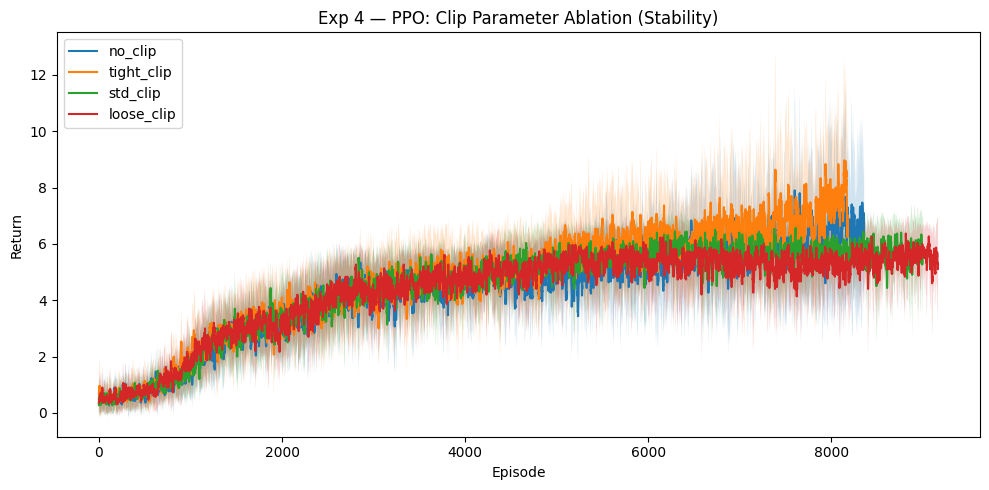


 Exp 4: PPO Clip Parameter Ablation
  no_clip                      6.95 +/- 1.08
  tight_clip                   8.63 +/- 0.34
  std_clip                     5.73 +/- 0.32
  loose_clip                   5.35 +/- 0.27


In [7]:
# Exp 4 — PPO Clip Parameter Ablation (Stability)
# Question: how does the clip parameter affect training stability?
# clip_coef=1.0 disables clipping entirely (equivalent to REINFORCE).
# The clip parameter limits how much the policy can change in one update.
 
clip_variants = [
    {"label": "no_clip",    "clip_coef": 1.0},
    {"label": "tight_clip", "clip_coef": 0.1},
    {"label": "std_clip",   "clip_coef": 0.2},
    {"label": "loose_clip", "clip_coef": 0.4},
]
 
exp4 = {}
for v in clip_variants:
    label = v["label"]
    exp4[label] = []
    for seed in SEEDS:
        cached = load_run("exp4", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp4 | {label} | seed={seed} — already completed")
            exp4[label].append(cached)
            continue
        cfg = {
            "game": GAME, "seed": seed, "total_steps": TOTAL_STEPS,
            "n_steps": 128, "n_epochs": 4, "batch_size": 32,
            "lr": 2.5e-4, "gamma": 0.99, "gae_lambda": 0.95,
            "ent_coef": 0.01, "vf_coef": 0.5, "max_grad_norm": 0.5,
            "snapshot_steps": SNAPSHOT_STEPS,
            "clip_coef": v["clip_coef"],
        }
        print(f"\n[Exp4] {label} | seed={seed}")
        rets, _ = train_ppo(cfg, run_name=f"ppo_{label}_s{seed}", use_wandb=True)
        exp4[label].append(rets)
        save_run("exp4", label, seed, rets)
 
plot_returns_with_std(exp4, title="Exp 4 — PPO: Clip Parameter Ablation (Stability)")
summarise_results(exp4, "Exp 4: PPO Clip Parameter Ablation")


[Exp5] high_freq | seed=0


Step  10,000 | Episodes:  874 | Avg return (last 20): 0.20 | Eps: 0.960
Step  20,000 | Episodes: 1705 | Avg return (last 20): 0.65 | Eps: 0.921
Step  30,000 | Episodes: 2481 | Avg return (last 20): 0.45 | Eps: 0.881
Step  40,000 | Episodes: 3192 | Avg return (last 20): 0.50 | Eps: 0.842
Step  50,000 | Episodes: 3896 | Avg return (last 20): 0.90 | Eps: 0.802
Step  60,000 | Episodes: 4575 | Avg return (last 20): 1.00 | Eps: 0.762
Step  70,000 | Episodes: 5201 | Avg return (last 20): 1.00 | Eps: 0.723
Step  80,000 | Episodes: 5768 | Avg return (last 20): 1.05 | Eps: 0.683
Step  90,000 | Episodes: 6313 | Avg return (last 20): 1.15 | Eps: 0.644
Step 100,000 | Episodes: 6825 | Avg return (last 20): 1.70 | Eps: 0.604
Step 110,000 | Episodes: 7254 | Avg return (last 20): 1.60 | Eps: 0.564
Step 120,000 | Episodes: 7656 | Avg return (last 20): 1.80 | Eps: 0.525
Step 130,000 | Episodes: 8058 | Avg return (last 20): 1.75 | Eps: 0.485
Step 140,000 | Episodes: 8433 | Avg return (last 20): 1.75 | Eps

buffer_size,▁▁▁▁▁▂▂▂▂▃▃▃▄▄▄▅▅▆▆▆▆▆▇█████████████████
episode,▁▁▁▂▂▂▂▂▂▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇███
episode_return,▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▂▂▁▁▂▂▁▂▁▄▁▄▂▁▅▅▃█
epsilon,██████▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▄▄▄▄▄▃▃▃▃▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▂▂▁▂▂▂▁▃▂▁▂▁▇▂█▂▃▄▂▂▁▂▁▇▁▁▂▁▁▁▂▁▁▁▂▁
step,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▆█
buffer_size,100000
episode,13294
episode_return,16
epsilon,0.01
loss,0.07823


  [SAVED] /kaggle/working/results/exp5_high_freq_s0.json

[Exp5] high_freq | seed=1


Step  10,000 | Episodes:  917 | Avg return (last 20): 0.90 | Eps: 0.960
Step  20,000 | Episodes: 1712 | Avg return (last 20): 0.25 | Eps: 0.921
Step  30,000 | Episodes: 2451 | Avg return (last 20): 0.75 | Eps: 0.881
Step  40,000 | Episodes: 3180 | Avg return (last 20): 0.85 | Eps: 0.842
Step  50,000 | Episodes: 3904 | Avg return (last 20): 0.90 | Eps: 0.802
Step  60,000 | Episodes: 4606 | Avg return (last 20): 0.60 | Eps: 0.762
Step  70,000 | Episodes: 5212 | Avg return (last 20): 1.20 | Eps: 0.723
Step  80,000 | Episodes: 5810 | Avg return (last 20): 1.35 | Eps: 0.683
Step  90,000 | Episodes: 6341 | Avg return (last 20): 1.25 | Eps: 0.644
Step 100,000 | Episodes: 6857 | Avg return (last 20): 1.60 | Eps: 0.604
Step 110,000 | Episodes: 7314 | Avg return (last 20): 1.55 | Eps: 0.564
Step 120,000 | Episodes: 7715 | Avg return (last 20): 1.75 | Eps: 0.525
Step 130,000 | Episodes: 8113 | Avg return (last 20): 2.10 | Eps: 0.485
Step 140,000 | Episodes: 8484 | Avg return (last 20): 2.50 | Eps

buffer_size,▁▁▁▂▂▃▃▃▃▃▃▃▄▄▄▄▅▅▆▆▇▇▇▇▇███████████████
episode,▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇█████
episode_return,▁▁▁▁▁▁▁▁▂▁▂▂▁▂▁▁▁▁▂▁▁▂▂▂▁▂▁▂▂▁▃▃▃▄▄▃▄▆▁█
epsilon,█████▇▇▇▇▇▇▇▇▆▆▆▅▅▅▅▅▅▄▄▄▄▄▄▃▃▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▄▃▂▇▂▄▁▂▄▂▂▁▁█▄▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▃▃▄▄▄▅▅▅▅▆▆▇█
buffer_size,100000
episode,13497
episode_return,9
epsilon,0.01
loss,0.04082


  [SAVED] /kaggle/working/results/exp5_high_freq_s1.json

[Exp5] high_freq | seed=2


Step  10,000 | Episodes:  887 | Avg return (last 20): 0.45 | Eps: 0.960
Step  20,000 | Episodes: 1747 | Avg return (last 20): 0.45 | Eps: 0.921
Step  30,000 | Episodes: 2492 | Avg return (last 20): 0.95 | Eps: 0.881
Step  40,000 | Episodes: 3214 | Avg return (last 20): 0.95 | Eps: 0.842
Step  50,000 | Episodes: 3885 | Avg return (last 20): 1.05 | Eps: 0.802
Step  60,000 | Episodes: 4540 | Avg return (last 20): 0.85 | Eps: 0.762
Step  70,000 | Episodes: 5139 | Avg return (last 20): 1.20 | Eps: 0.723
Step  80,000 | Episodes: 5711 | Avg return (last 20): 1.10 | Eps: 0.683
Step  90,000 | Episodes: 6243 | Avg return (last 20): 1.50 | Eps: 0.644
Step 100,000 | Episodes: 6730 | Avg return (last 20): 1.30 | Eps: 0.604
Step 110,000 | Episodes: 7194 | Avg return (last 20): 1.65 | Eps: 0.564
Step 120,000 | Episodes: 7624 | Avg return (last 20): 1.75 | Eps: 0.525
Step 130,000 | Episodes: 8001 | Avg return (last 20): 2.00 | Eps: 0.485
Step 140,000 | Episodes: 8384 | Avg return (last 20): 1.70 | Eps

buffer_size,▁▁▁▁▁▂▂▂▃▃▄▄▄▅▅▅▆▆▆▇▇███████████████████
episode,▁▁▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇▇█████
episode_return,▁▂▁▂▂▁▁▁▁▂▂▁▂▂▂▂▂▂▁▂▃▂▁▂▁▂▅▂▃▅▂▂▆▇▇▅▇█▅▁
epsilon,█████▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▅▅▅▅▅▄▄▃▃▃▃▃▂▂▂▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▄▂▁▇▁▂▄▂█▁▆▆▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▆▆▆▇▇▇▇█
buffer_size,100000
episode,13779
episode_return,21
epsilon,0.01
loss,0.1726


  [SAVED] /kaggle/working/results/exp5_high_freq_s2.json

[Exp5] std_freq | seed=0


Step  10,000 | Episodes:  886 | Avg return (last 20): 0.40 | Eps: 0.960
Step  20,000 | Episodes: 1733 | Avg return (last 20): 0.50 | Eps: 0.921
Step  30,000 | Episodes: 2479 | Avg return (last 20): 0.55 | Eps: 0.881
Step  40,000 | Episodes: 3194 | Avg return (last 20): 0.65 | Eps: 0.842
Step  50,000 | Episodes: 3854 | Avg return (last 20): 0.75 | Eps: 0.802
Step  60,000 | Episodes: 4490 | Avg return (last 20): 1.50 | Eps: 0.762
Step  70,000 | Episodes: 5080 | Avg return (last 20): 1.20 | Eps: 0.723
Step  80,000 | Episodes: 5650 | Avg return (last 20): 1.50 | Eps: 0.683
Step  90,000 | Episodes: 6164 | Avg return (last 20): 0.95 | Eps: 0.644
Step 100,000 | Episodes: 6644 | Avg return (last 20): 1.75 | Eps: 0.604
Step 110,000 | Episodes: 7106 | Avg return (last 20): 1.55 | Eps: 0.564
Step 120,000 | Episodes: 7525 | Avg return (last 20): 2.45 | Eps: 0.525
Step 130,000 | Episodes: 7931 | Avg return (last 20): 1.75 | Eps: 0.485
Step 140,000 | Episodes: 8327 | Avg return (last 20): 1.40 | Eps

buffer_size,▁▁▁▂▂▃▃▃▃▄▅▅▆▆▆▇▇▇██████████████████████
episode,▁▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▆▇▇▇▇██
episode_return,▁▁▁▁▁▁▁▂▁▂▁▁▁▁▁▂▁▁▂▁▁▂▂▂▂▂▂▁▂▂▁▁▁▂▂▃▃▄▃█
epsilon,█████████▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▅▅▅▅▃▃▃▃▃▂▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▄▁▁▁▁▁▁▁▇█▁▂▂▁▁▁▂▁▂▂▁▁
step,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▆▇█
buffer_size,100000
episode,13271
episode_return,11
epsilon,0.01
loss,0.05412


  [SAVED] /kaggle/working/results/exp5_std_freq_s0.json

[Exp5] std_freq | seed=1


Step  10,000 | Episodes:  881 | Avg return (last 20): 0.70 | Eps: 0.960
Step  20,000 | Episodes: 1684 | Avg return (last 20): 0.80 | Eps: 0.921
Step  30,000 | Episodes: 2428 | Avg return (last 20): 0.75 | Eps: 0.881
Step  40,000 | Episodes: 3121 | Avg return (last 20): 0.30 | Eps: 0.842
Step  50,000 | Episodes: 3786 | Avg return (last 20): 1.25 | Eps: 0.802
Step  60,000 | Episodes: 4415 | Avg return (last 20): 1.15 | Eps: 0.762
Step  70,000 | Episodes: 4969 | Avg return (last 20): 1.05 | Eps: 0.723
Step  80,000 | Episodes: 5474 | Avg return (last 20): 1.95 | Eps: 0.683
Step  90,000 | Episodes: 5991 | Avg return (last 20): 1.25 | Eps: 0.644
Step 100,000 | Episodes: 6451 | Avg return (last 20): 1.25 | Eps: 0.604
Step 110,000 | Episodes: 6911 | Avg return (last 20): 1.10 | Eps: 0.564
Step 120,000 | Episodes: 7353 | Avg return (last 20): 1.75 | Eps: 0.525
Step 130,000 | Episodes: 7718 | Avg return (last 20): 2.10 | Eps: 0.485
Step 140,000 | Episodes: 8068 | Avg return (last 20): 2.35 | Eps

buffer_size,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▆▆▇▇▇▇████████████████
episode,▁▁▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▄▄▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇██
episode_return,▁▁▁▂▁▁▁▁▂▁▁▁▂▁▁▂▁▂▃▂▃▁▁▃▁▁▅▂▁▃▃▄▄▃▁▆▁█▆▇
epsilon,█████▇▇▇▇▆▆▆▆▆▆▆▅▅▅▅▅▅▄▄▄▃▃▂▂▂▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▃▁▅▇█▁▁▂▅▁▁▂▁▂▁▂▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▇▇▇██
buffer_size,100000
episode,12805
episode_return,10
epsilon,0.01
loss,0.06251


  [SAVED] /kaggle/working/results/exp5_std_freq_s1.json

[Exp5] std_freq | seed=2


Step  10,000 | Episodes:  882 | Avg return (last 20): 0.30 | Eps: 0.960
Step  20,000 | Episodes: 1720 | Avg return (last 20): 0.80 | Eps: 0.921
Step  30,000 | Episodes: 2466 | Avg return (last 20): 0.75 | Eps: 0.881
Step  40,000 | Episodes: 3143 | Avg return (last 20): 1.05 | Eps: 0.842
Step  50,000 | Episodes: 3821 | Avg return (last 20): 0.75 | Eps: 0.802
Step  60,000 | Episodes: 4453 | Avg return (last 20): 0.95 | Eps: 0.762
Step  70,000 | Episodes: 5001 | Avg return (last 20): 1.20 | Eps: 0.723
Step  80,000 | Episodes: 5556 | Avg return (last 20): 1.30 | Eps: 0.683
Step  90,000 | Episodes: 6060 | Avg return (last 20): 1.00 | Eps: 0.644
Step 100,000 | Episodes: 6532 | Avg return (last 20): 0.80 | Eps: 0.604
Step 110,000 | Episodes: 6963 | Avg return (last 20): 1.95 | Eps: 0.564
Step 120,000 | Episodes: 7395 | Avg return (last 20): 1.80 | Eps: 0.525
Step 130,000 | Episodes: 7738 | Avg return (last 20): 1.65 | Eps: 0.485
Step 140,000 | Episodes: 8086 | Avg return (last 20): 1.60 | Eps

buffer_size,▁▁▁▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▆▆▆▇▇▇▇▇██████████████
episode,▁▁▁▁▂▂▂▂▂▃▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇█████
episode_return,▂▁▁▂▁▂▁▂▁▃▁▁▃▁▂▄▂▅▂▁▂▅▄▂▂▁▃▂▂▆▂▆▅▇█▅▁▄▇▁
epsilon,█████▇▇▇▇▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▅▄▃▃▃▃▃▂▂▂▂▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▂▁▂▁▁▂▁▁▂▁▂█▂▃▂▂▂▂▁▂▁▁▁▂▁▁▁▁▂▂▁
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▃▄▄▅▅▆▆▆▇▇▇▇█
buffer_size,100000
episode,12705
episode_return,22
epsilon,0.01
loss,0.06415


  [SAVED] /kaggle/working/results/exp5_std_freq_s2.json

[Exp5] low_freq | seed=0


Step  10,000 | Episodes:  910 | Avg return (last 20): 0.50 | Eps: 0.960
Step  20,000 | Episodes: 1751 | Avg return (last 20): 0.90 | Eps: 0.921
Step  30,000 | Episodes: 2556 | Avg return (last 20): 0.70 | Eps: 0.881
Step  40,000 | Episodes: 3306 | Avg return (last 20): 0.65 | Eps: 0.842
Step  50,000 | Episodes: 4015 | Avg return (last 20): 0.60 | Eps: 0.802
Step  60,000 | Episodes: 4731 | Avg return (last 20): 0.80 | Eps: 0.762
Step  70,000 | Episodes: 5397 | Avg return (last 20): 0.85 | Eps: 0.723
Step  80,000 | Episodes: 5973 | Avg return (last 20): 1.25 | Eps: 0.683
Step  90,000 | Episodes: 6541 | Avg return (last 20): 0.90 | Eps: 0.644
Step 100,000 | Episodes: 7047 | Avg return (last 20): 1.20 | Eps: 0.604
Step 110,000 | Episodes: 7500 | Avg return (last 20): 1.40 | Eps: 0.564
Step 120,000 | Episodes: 7947 | Avg return (last 20): 1.70 | Eps: 0.525
Step 130,000 | Episodes: 8308 | Avg return (last 20): 1.85 | Eps: 0.485
Step 140,000 | Episodes: 8635 | Avg return (last 20): 2.35 | Eps

buffer_size,▁▁▁▂▂▃▃▃▃▄▅▅▅▆▆▇▇▇██████████████████████
episode,▁▁▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▆▆▆▇▇▇▇▇▇▇▇███████
episode_return,▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▂▁▁▁▁▁▁▂▁▁▁▁▃▃▃█▂▃▃█▅▁▄▆▆
epsilon,████████████▇▇▇▇▇▇▇▆▆▆▆▆▅▅▅▄▄▄▄▄▃▃▃▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▄█▁▁▁▁▁▂▂▁
step,▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▄▅▅▇▇▇█
buffer_size,100000
episode,13538
episode_return,9
epsilon,0.01
loss,0.03825


  [SAVED] /kaggle/working/results/exp5_low_freq_s0.json

[Exp5] low_freq | seed=1


Step  10,000 | Episodes:  897 | Avg return (last 20): 0.60 | Eps: 0.960
Step  20,000 | Episodes: 1779 | Avg return (last 20): 0.55 | Eps: 0.921
Step  30,000 | Episodes: 2599 | Avg return (last 20): 0.25 | Eps: 0.881
Step  40,000 | Episodes: 3372 | Avg return (last 20): 0.95 | Eps: 0.842
Step  50,000 | Episodes: 4083 | Avg return (last 20): 0.80 | Eps: 0.802
Step  60,000 | Episodes: 4778 | Avg return (last 20): 0.95 | Eps: 0.762
Step  70,000 | Episodes: 5455 | Avg return (last 20): 0.85 | Eps: 0.723
Step  80,000 | Episodes: 6047 | Avg return (last 20): 1.10 | Eps: 0.683
Step  90,000 | Episodes: 6596 | Avg return (last 20): 1.30 | Eps: 0.644
Step 100,000 | Episodes: 7100 | Avg return (last 20): 1.55 | Eps: 0.604
Step 110,000 | Episodes: 7573 | Avg return (last 20): 2.10 | Eps: 0.564
Step 120,000 | Episodes: 8001 | Avg return (last 20): 1.00 | Eps: 0.525
Step 130,000 | Episodes: 8365 | Avg return (last 20): 1.95 | Eps: 0.485
Step 140,000 | Episodes: 8745 | Avg return (last 20): 1.75 | Eps

buffer_size,▁▁▂▂▃▃▃▃▄▅▅▅▇▇▇█████████████████████████
episode,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▄▄▅▅▅▆▆▆▆▇▇▇▇▇███
episode_return,▂▂▂▂▂▂▂▁▂▁▁▂▂▁▁▁▂▂▁▁▁▂▂▂▄▂▁▃▃▃▂▃▄▆▂▃▄▁▆█
epsilon,████████████▇▇▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▅▅▄▄▃▃▁▁▁▁▁
loss,▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▃▂▂▁▁▂▂▁▄▁▁▁▂▂▁▂▁▂▂▃▃▂▃▆█
step,▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▄▅▅▅▆▆█
buffer_size,100000
episode,13447
episode_return,17
epsilon,0.01
loss,0.01792


  [SAVED] /kaggle/working/results/exp5_low_freq_s1.json

[Exp5] low_freq | seed=2


Step  10,000 | Episodes:  898 | Avg return (last 20): 0.40 | Eps: 0.960
Step  20,000 | Episodes: 1735 | Avg return (last 20): 0.45 | Eps: 0.921
Step  30,000 | Episodes: 2509 | Avg return (last 20): 0.40 | Eps: 0.881
Step  40,000 | Episodes: 3242 | Avg return (last 20): 0.85 | Eps: 0.842
Step  50,000 | Episodes: 3952 | Avg return (last 20): 0.60 | Eps: 0.802
Step  60,000 | Episodes: 4621 | Avg return (last 20): 0.95 | Eps: 0.762
Step  70,000 | Episodes: 5288 | Avg return (last 20): 0.50 | Eps: 0.723
Step  80,000 | Episodes: 5946 | Avg return (last 20): 1.05 | Eps: 0.683
Step  90,000 | Episodes: 6488 | Avg return (last 20): 0.95 | Eps: 0.644
Step 100,000 | Episodes: 7008 | Avg return (last 20): 1.35 | Eps: 0.604
Step 110,000 | Episodes: 7469 | Avg return (last 20): 1.90 | Eps: 0.564
Step 120,000 | Episodes: 7906 | Avg return (last 20): 1.50 | Eps: 0.525
Step 130,000 | Episodes: 8307 | Avg return (last 20): 1.95 | Eps: 0.485
Step 140,000 | Episodes: 8700 | Avg return (last 20): 1.25 | Eps

buffer_size,▁▁▁▂▂▂▂▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇████████████
episode,▁▁▁▁▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▄▅▅▅▅▆▆▆▆▆▆▇▇▇▇▇█████
episode_return,▁▁▁▁▁▁▁▁▂▁▁▁▁▁▂▂▁▁▂▁▁▁▂▁▃▂▂▁▂▃▂▂▃▄▄▂▅▁██
epsilon,███▇▇▇▇▇▇▇▇▇▆▆▆▆▆▆▆▆▅▅▅▅▄▄▄▃▃▂▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁█▅
step,▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▆▆▆▆▇▇▇█
buffer_size,100000
episode,13791
episode_return,0
epsilon,0.01
loss,0.55799


  [SAVED] /kaggle/working/results/exp5_low_freq_s2.json


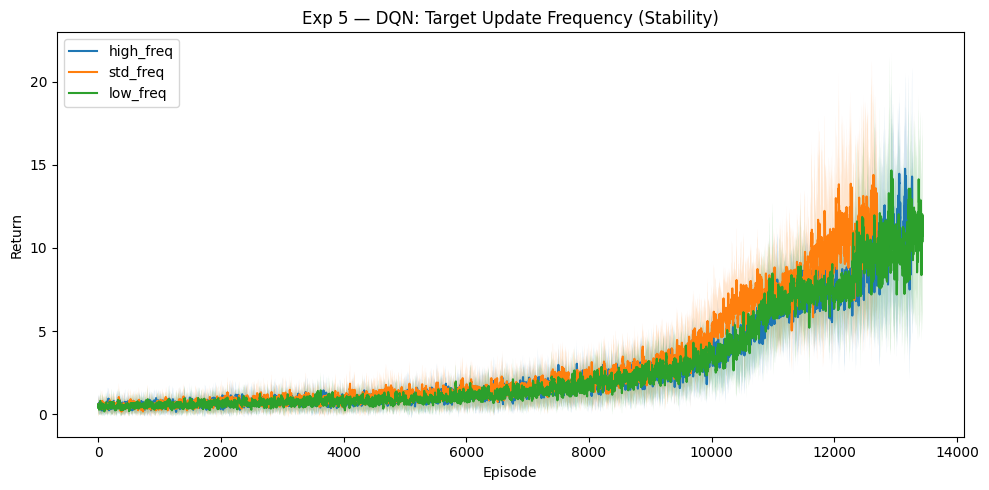


 Exp 5: DQN Target Update Frequency
  high_freq                    12.52 +/- 0.20
  std_freq                     9.67 +/- 1.82
  low_freq                     12.75 +/- 1.09


In [8]:
# Exp 5 — DQN Target Update Frequency (Stability)
# Question: how does the frequency of target network updates affect stability?
# High frequency (100): target moves fast -> more instability
# Standard (1000): good compromise, used in Mnih et al. 2015
# Low frequency (10000): very stable targets but potentially outdated
 
target_freq_variants = [
    {"label": "high_freq", "target_update_freq": 100},
    {"label": "std_freq",  "target_update_freq": 1000},
    {"label": "low_freq",  "target_update_freq": 10000},
]
 
exp5 = {}
for v in target_freq_variants:
    label = v["label"]
    exp5[label] = []
    for seed in SEEDS:
        cached = load_run("exp5", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp5 | {label} | seed={seed} — already completed")
            exp5[label].append(cached)
            continue
        cfg = {
            "game": GAME, "seed": seed, "total_steps": TOTAL_STEPS,
            "batch_size": 32, "buffer_size": 100_000,
            "lr": 1e-4, "gamma": 0.99,
            "eps_start": 1.0, "eps_end": 0.01, "eps_decay_steps": 250_000,
            "snapshot_steps": SNAPSHOT_STEPS,
            "target_update_freq": v["target_update_freq"],
        }
        print(f"\n[Exp5] {label} | seed={seed}")
        rets, _ = train_dqn(cfg, run_name=f"dqn_{label}_s{seed}", use_wandb=True)
        exp5[label].append(rets)
        save_run("exp5", label, seed, rets)
 
plot_returns_with_std(exp5, title="Exp 5 — DQN: Target Update Frequency (Stability)")
summarise_results(exp5, "Exp 5: DQN Target Update Frequency")


[SKIP] exp6 | lambda_0 | seed=0 — already completed

[SKIP] exp6 | lambda_0 | seed=1 — already completed

[SKIP] exp6 | lambda_0 | seed=2 — already completed

[SKIP] exp6 | lambda_095 | seed=0 — already completed

[SKIP] exp6 | lambda_095 | seed=1 — already completed

[SKIP] exp6 | lambda_095 | seed=2 — already completed

[SKIP] exp6 | lambda_1 | seed=0 — already completed

[SKIP] exp6 | lambda_1 | seed=1 — already completed

[SKIP] exp6 | lambda_1 | seed=2 — already completed


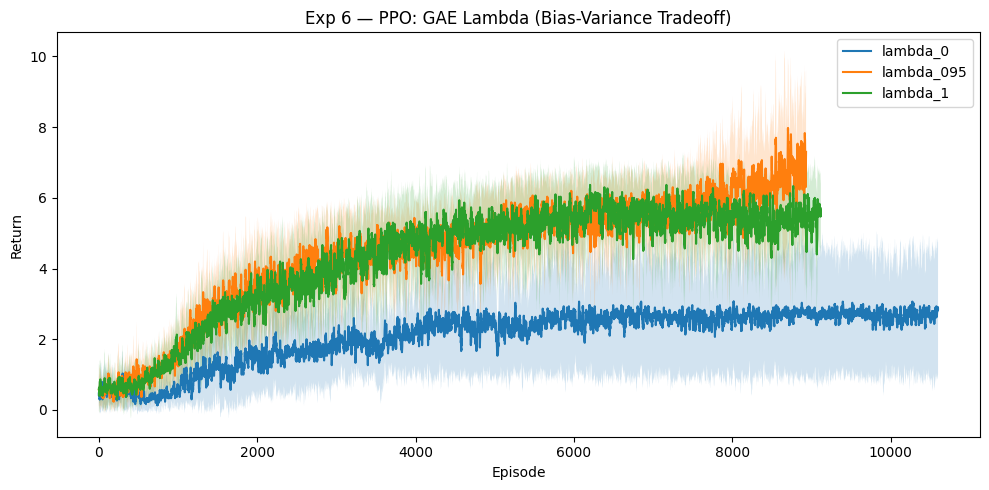


 Exp 6: PPO GAE Lambda
  lambda_0                     4.28 +/- 1.07
  lambda_095                   6.87 +/- 1.17
  lambda_1                     5.78 +/- 0.49


In [10]:
# Exp 6 — PPO GAE Lambda (Bias-Variance Tradeoff)
# Question: how does GAE lambda affect the bias-variance tradeoff in
# advantage estimation?
#
# lambda=0  -> pure TD(0): A_t = delta_t
#              high bias (depends on value network accuracy), low variance
# lambda=1  -> Monte Carlo: A_t = sum of discounted rewards - V(s)
#              low bias, high variance (accumulates noise over full episode)
# lambda=0.95 -> standard compromise (Schulman et al., 2017)
#
 
lambda_variants = [
    {"label": "lambda_0",   "gae_lambda": 0.0},
    {"label": "lambda_095", "gae_lambda": 0.95},
    {"label": "lambda_1",   "gae_lambda": 1.0},
]
 
exp6 = {}
for v in lambda_variants:
    label = v["label"]
    exp6[label] = []
    for seed in SEEDS:
        cached = load_run("exp6", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp6 | {label} | seed={seed} — already completed")
            exp6[label].append(cached)
            continue
        cfg = {
            "game": GAME, "seed": seed, "total_steps": TOTAL_STEPS,
            "n_steps": 128, "n_epochs": 4, "batch_size": 32,
            "lr": 2.5e-4, "gamma": 0.99,
            "clip_coef": 0.2, "ent_coef": 0.01, "vf_coef": 0.5,
            "max_grad_norm": 0.5, "snapshot_steps": SNAPSHOT_STEPS,
            "gae_lambda": v["gae_lambda"],
        }
        print(f"\n[Exp6] {label} | seed={seed}")
        rets, _ = train_ppo(cfg, run_name=f"ppo_{label}_s{seed}", use_wandb=True)
        exp6[label].append(rets)
        save_run("exp6", label, seed, rets)
 
plot_returns_with_std(exp6, title="Exp 6 — PPO: GAE Lambda (Bias-Variance Tradeoff)")
summarise_results(exp6, "Exp 6: PPO GAE Lambda")


[Exp7] dqn_default | seed=0


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Step  10,000 | Episodes:  911 | Avg return (last 20): 0.60 | Eps: 0.960
Step  20,000 | Episodes: 1709 | Avg return (last 20): 0.60 | Eps: 0.921
Step  30,000 | Episodes: 2457 | Avg return (last 20): 0.40 | Eps: 0.881
Step  40,000 | Episodes: 3155 | Avg return (last 20): 0.90 | Eps: 0.842
Step  50,000 | Episodes: 3870 | Avg return (last 20): 0.85 | Eps: 0.802
Step  60,000 | Episodes: 4467 | Avg return (last 20): 1.05 | Eps: 0.762
Step  70,000 | Episodes: 5022 | Avg return (last 20): 1.10 | Eps: 0.723
Step  80,000 | Episodes: 5555 | Avg return (last 20): 1.25 | Eps: 0.683
Step  90,000 | Episodes: 6059 | Avg return (last 20): 1.55 | Eps: 0.644
Step 100,000 | Episodes: 6534 | Avg return (last 20): 1.55 | Eps: 0.604
Step 110,000 | Episodes: 6967 | Avg return (last 20): 1.75 | Eps: 0.564
Step 120,000 | Episodes: 7396 | Avg return (last 20): 1.55 | Eps: 0.525
Step 130,000 | Episodes: 7759 | Avg return (last 20): 1.95 | Eps: 0.485
Step 140,000 | Episodes: 8093 | Avg return (last 20): 2.00 | Eps

buffer_size,▁▁▂▂▃▄▅▅▅▆▆▆▆▇▇█████████████████████████
episode,▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇█████
episode_return,▁▁▁▁▁▂▁▁▂▂▂▂▂▁▂▁▁▃▁▁▁▂▁▂▃▁▃▃▄▃▄▆▃▄▆▂██▅▇
epsilon,███▇▇▇▆▆▆▆▅▅▅▅▅▄▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▁▁▁▁▁▁▁█▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▃▃▃▄▄▄▄▅▆█
buffer_size,100000
episode,16025
episode_return,12
epsilon,0.01
loss,0.22613


  [SAVED] /kaggle/working/results/exp7_dqn_default_s0.json

[Exp7] dqn_default | seed=1


Step  10,000 | Episodes:  860 | Avg return (last 20): 0.70 | Eps: 0.960
Step  20,000 | Episodes: 1658 | Avg return (last 20): 0.55 | Eps: 0.921
Step  30,000 | Episodes: 2424 | Avg return (last 20): 0.80 | Eps: 0.881
Step  40,000 | Episodes: 3084 | Avg return (last 20): 1.05 | Eps: 0.842
Step  50,000 | Episodes: 3741 | Avg return (last 20): 0.90 | Eps: 0.802
Step  60,000 | Episodes: 4397 | Avg return (last 20): 0.40 | Eps: 0.762
Step  70,000 | Episodes: 4976 | Avg return (last 20): 1.15 | Eps: 0.723
Step  80,000 | Episodes: 5496 | Avg return (last 20): 1.35 | Eps: 0.683
Step  90,000 | Episodes: 6022 | Avg return (last 20): 1.00 | Eps: 0.644
Step 100,000 | Episodes: 6500 | Avg return (last 20): 1.25 | Eps: 0.604
Step 110,000 | Episodes: 6935 | Avg return (last 20): 1.45 | Eps: 0.564
Step 120,000 | Episodes: 7365 | Avg return (last 20): 1.65 | Eps: 0.525
Step 130,000 | Episodes: 7735 | Avg return (last 20): 2.80 | Eps: 0.485
Step 140,000 | Episodes: 8086 | Avg return (last 20): 2.80 | Eps

buffer_size,▁▁▁▂▂▂▃▃▃▃▄▅▆▆▆▇████████████████████████
episode,▁▁▁▁▁▁▂▂▂▂▃▃▃▃▃▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇▇█
episode_return,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▁▁▂▂▂▁▁▃▃▃▂▄▅▄▅▁█▃▄█
epsilon,████▇▇▇▇▇▇▇▇▇▆▆▆▆▅▅▅▅▅▅▅▅▃▃▃▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁█▁▅▂▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▃▃▄▄▄▅▅▆▆█
buffer_size,100000
episode,15308
episode_return,20
epsilon,0.01
loss,0.05168


  [SAVED] /kaggle/working/results/exp7_dqn_default_s1.json

[Exp7] dqn_default | seed=2


Step  10,000 | Episodes:  861 | Avg return (last 20): 0.40 | Eps: 0.960
Step  20,000 | Episodes: 1690 | Avg return (last 20): 0.55 | Eps: 0.921
Step  30,000 | Episodes: 2453 | Avg return (last 20): 1.20 | Eps: 0.881
Step  40,000 | Episodes: 3175 | Avg return (last 20): 0.70 | Eps: 0.842
Step  50,000 | Episodes: 3874 | Avg return (last 20): 0.75 | Eps: 0.802
Step  60,000 | Episodes: 4501 | Avg return (last 20): 0.95 | Eps: 0.762
Step  70,000 | Episodes: 5093 | Avg return (last 20): 0.70 | Eps: 0.723
Step  80,000 | Episodes: 5643 | Avg return (last 20): 1.55 | Eps: 0.683
Step  90,000 | Episodes: 6209 | Avg return (last 20): 1.00 | Eps: 0.644
Step 100,000 | Episodes: 6696 | Avg return (last 20): 1.60 | Eps: 0.604
Step 110,000 | Episodes: 7127 | Avg return (last 20): 1.60 | Eps: 0.564
Step 120,000 | Episodes: 7543 | Avg return (last 20): 1.65 | Eps: 0.525
Step 130,000 | Episodes: 7910 | Avg return (last 20): 2.65 | Eps: 0.485
Step 140,000 | Episodes: 8287 | Avg return (last 20): 1.80 | Eps

buffer_size,▁▁▁▁▂▂▃▃▃▃▃▃▄▄▄▆▆███████████████████████
episode,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇█
episode_return,▁▁▁▁▁▂▂▁▁▁▁▁▁▁▁▁▁▂▁▁▁▂▁▁▁▁▃▁▂▁▂▃▂▁▄▄▅▁▃█
epsilon,██▇▇▇▇▇▇▇▆▆▆▆▅▅▅▅▅▅▄▄▄▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▄█▂▃▄▁▃▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▂▂▂▂▂▃▃▃▃▃▄▅▅▆▇▇█
buffer_size,100000
episode,14859
episode_return,7
epsilon,0.01
loss,0.06678


  [SAVED] /kaggle/working/results/exp7_dqn_default_s2.json

[Exp7] dqn_best | seed=0


Step  10,000 | Episodes:  755 | Avg return (last 20): 0.65 | Eps: 0.480
Step  20,000 | Episodes: 1365 | Avg return (last 20): 0.90 | Eps: 0.461
Step  30,000 | Episodes: 1857 | Avg return (last 20): 1.20 | Eps: 0.441
Step  40,000 | Episodes: 2338 | Avg return (last 20): 1.35 | Eps: 0.422
Step  50,000 | Episodes: 2793 | Avg return (last 20): 1.70 | Eps: 0.402
Step  60,000 | Episodes: 3250 | Avg return (last 20): 1.45 | Eps: 0.382
Step  70,000 | Episodes: 3665 | Avg return (last 20): 1.50 | Eps: 0.363
Step  80,000 | Episodes: 4052 | Avg return (last 20): 1.70 | Eps: 0.343
Step  90,000 | Episodes: 4415 | Avg return (last 20): 1.85 | Eps: 0.324
Step 100,000 | Episodes: 4743 | Avg return (last 20): 2.15 | Eps: 0.304
Step 110,000 | Episodes: 5037 | Avg return (last 20): 2.95 | Eps: 0.284
Step 120,000 | Episodes: 5318 | Avg return (last 20): 3.00 | Eps: 0.265
Step 130,000 | Episodes: 5581 | Avg return (last 20): 3.20 | Eps: 0.245
Step 140,000 | Episodes: 5818 | Avg return (last 20): 3.85 | Eps

buffer_size,▁▁▁▁▂▄▄▅▅▆▆▆▇▇██████████████████████████
episode,▁▁▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇███
episode_return,▁▁▁▁▂▁▁▁▁▁▂▁▁▁▁▁▁▁▁▂▁▂▂▁▂▃▃▃▃▇▇▄▅▄▃█▇▃▆▁
epsilon,███▇▇▇▇▇▇▆▆▆▆▆▅▄▄▃▃▃▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▂▁▁▁▁▁▁▁▂▁▂▂▁▁▁▁▁▂▁▂▂▂▁▁▁▃▃▃▂▂█▄▅▂▃▃▄▂▇▅
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▄▄▄▅▅▆▆▆▇▇▇▇▇▇█
buffer_size,100000
episode,13464
episode_return,23
epsilon,0.01
loss,0.08484


  [SAVED] /kaggle/working/results/exp7_dqn_best_s0.json

[Exp7] dqn_best | seed=1


Step  10,000 | Episodes:  794 | Avg return (last 20): 0.70 | Eps: 0.480
Step  20,000 | Episodes: 1380 | Avg return (last 20): 1.45 | Eps: 0.461
Step  30,000 | Episodes: 1917 | Avg return (last 20): 0.90 | Eps: 0.441
Step  40,000 | Episodes: 2384 | Avg return (last 20): 1.10 | Eps: 0.422
Step  50,000 | Episodes: 2816 | Avg return (last 20): 1.75 | Eps: 0.402
Step  60,000 | Episodes: 3284 | Avg return (last 20): 1.40 | Eps: 0.382
Step  70,000 | Episodes: 3720 | Avg return (last 20): 1.15 | Eps: 0.363
Step  80,000 | Episodes: 4112 | Avg return (last 20): 1.65 | Eps: 0.343
Step  90,000 | Episodes: 4462 | Avg return (last 20): 2.40 | Eps: 0.324
Step 100,000 | Episodes: 4790 | Avg return (last 20): 2.30 | Eps: 0.304
Step 110,000 | Episodes: 5089 | Avg return (last 20): 2.85 | Eps: 0.284
Step 120,000 | Episodes: 5347 | Avg return (last 20): 2.60 | Eps: 0.265
Step 130,000 | Episodes: 5650 | Avg return (last 20): 2.55 | Eps: 0.245
Step 140,000 | Episodes: 5916 | Avg return (last 20): 2.70 | Eps

buffer_size,▁▂▂▂▂▃▄▄▄▅▆▆▇▇██████████████████████████
episode,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇██
episode_return,▁▁▁▁▁▁▁▁▁▂▁▁▂▂▁▁▂▂▁▁▂▃▁▃▃▄▃▃▇▅▄▁▃█▂▄▃▄▆▄
epsilon,███████▇▇▇▇▇▇▇▆▆▅▅▅▅▄▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁█▁▁▂▁▂▁▃▂▂▂▂▂
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▂▂▃▃▃▄▄▄▅▅▅▆▆▇▇▇█
buffer_size,100000
episode,13400
episode_return,28
epsilon,0.01
loss,0.0397


  [SAVED] /kaggle/working/results/exp7_dqn_best_s1.json

[Exp7] dqn_best | seed=2


Step  10,000 | Episodes:  776 | Avg return (last 20): 1.05 | Eps: 0.480
Step  20,000 | Episodes: 1448 | Avg return (last 20): 0.85 | Eps: 0.461
Step  30,000 | Episodes: 2022 | Avg return (last 20): 1.50 | Eps: 0.441
Step  40,000 | Episodes: 2540 | Avg return (last 20): 1.25 | Eps: 0.422
Step  50,000 | Episodes: 3007 | Avg return (last 20): 1.95 | Eps: 0.402
Step  60,000 | Episodes: 3485 | Avg return (last 20): 0.95 | Eps: 0.382
Step  70,000 | Episodes: 3930 | Avg return (last 20): 1.45 | Eps: 0.363
Step  80,000 | Episodes: 4331 | Avg return (last 20): 1.40 | Eps: 0.343
Step  90,000 | Episodes: 4730 | Avg return (last 20): 2.00 | Eps: 0.324
Step 100,000 | Episodes: 5053 | Avg return (last 20): 2.85 | Eps: 0.304
Step 110,000 | Episodes: 5383 | Avg return (last 20): 2.45 | Eps: 0.284
Step 120,000 | Episodes: 5673 | Avg return (last 20): 2.60 | Eps: 0.265
Step 130,000 | Episodes: 5928 | Avg return (last 20): 3.75 | Eps: 0.245
Step 140,000 | Episodes: 6182 | Avg return (last 20): 3.10 | Eps

buffer_size,▁▁▂▂▂▄▅▅▅▆▆▆▆▆▆▇████████████████████████
episode,▁▁▁▁▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇█████
episode_return,▁▁▁▁▁▁▁▁▁▁▂▁▁▁▂▂▁▁▁▁▂▁▂▃▃▁▃▁▃▃▃▁▆▄▃▅▇▄█▄
epsilon,█████▇▇▆▆▆▆▆▅▅▅▄▄▄▄▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▃▁▁▁▁▁▄▁▂▁▁▄▁█▁▁▁▁▂
step,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▃▃▃▃▄▄▅▅▅▅▆▆▆▇▇▇█
buffer_size,100000
episode,13777
episode_return,22
epsilon,0.01
loss,0.05337


  [SAVED] /kaggle/working/results/exp7_dqn_best_s2.json

[Exp7] ppo_default | seed=0


Step  80,000 | Episodes: 2744 | Avg return (last 20): 4.15
Step 160,000 | Episodes: 4238 | Avg return (last 20): 4.80
Step 240,000 | Episodes: 5575 | Avg return (last 20): 5.55
Step 320,000 | Episodes: 6906 | Avg return (last 20): 4.95
Step 400,000 | Episodes: 8234 | Avg return (last 20): 5.00
Step 480,000 | Episodes: 9448 | Avg return (last 20): 6.10
Step 560,000 | Episodes: 10605 | Avg return (last 20): 6.85
Step 640,000 | Episodes: 11532 | Avg return (last 20): 8.35
Step 720,000 | Episodes: 12362 | Avg return (last 20): 9.15
Step 800,000 | Episodes: 13197 | Avg return (last 20): 7.90
Step 880,000 | Episodes: 14055 | Avg return (last 20): 7.00
Step 960,000 | Episodes: 14916 | Avg return (last 20): 10.65


episode,▁▂▂▂▂▂▂▃▃▃▃▃▃▄▄▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇█████
episode_return,▁▂▂▃▃▃▄▄▅▄▅▄▄▅▅▅▅▄▅▄▅▅▅▅▅▇▇█▇▇▆█▇▇▇█▇▇▆█
policy_entropy,▆██▇▇▄▄▃▃▄▂▁▁▂▂▅▄▃▄▄▅▂▅▄▄▁▃▂▄▃▃▄▂▄▂▂▅▄▄▄
policy_loss,▇▂▂▇▆▃▃▅▇▇▆▇▅█▆▇▇▅▆▆▅▆▆▇▅▁▄▄▅▇▃▂▄▅█▅▆▃▂▃
step,▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▄▄▅▅▆▆▆▆▆▆▆▇▇▇▇▇█
total_loss,▂▃▃▂▁▃▂▂▂▁▁▁▁▁▁▁▁▃▁▂▁▁▁▂▃▁▄▁▁▁▃▂█▅▂▃▁▂▃▂
value_loss,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▂▁▂█
episode,15340
episode_return,8.65
policy_entropy,0.46842
policy_loss,-0.03465


  [SAVED] /kaggle/working/results/exp7_ppo_default_s0.json

[Exp7] ppo_default | seed=1


Step  80,000 | Episodes: 2538 | Avg return (last 20): 3.90
Step 160,000 | Episodes: 4055 | Avg return (last 20): 5.05
Step 240,000 | Episodes: 5398 | Avg return (last 20): 5.10
Step 320,000 | Episodes: 6614 | Avg return (last 20): 5.65
Step 400,000 | Episodes: 7827 | Avg return (last 20): 5.90
Step 480,000 | Episodes: 8861 | Avg return (last 20): 7.85
Step 560,000 | Episodes: 9776 | Avg return (last 20): 7.30
Step 640,000 | Episodes: 10694 | Avg return (last 20): 8.45
Step 720,000 | Episodes: 11551 | Avg return (last 20): 7.05
Step 800,000 | Episodes: 12333 | Avg return (last 20): 11.15
Step 880,000 | Episodes: 13062 | Avg return (last 20): 10.45
Step 960,000 | Episodes: 13830 | Avg return (last 20): 12.45


episode,▁▁▁▁▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇▇▇█
episode_return,▁▂▂▂▃▃▃▃▄▃▄▄▄▄▄▅▅▅▅▄▅▅▅▅▅▅▅▆▅▆▆█▇▆█▇▆▇▄▆
policy_entropy,█▇▅▅▅▆▅▅▅▅▄▄▃▁▂▃▂▄▄▂▂▃▃▂▂▂▃▃▃▃▃▁▁▃▄▂▁▃▂▂
policy_loss,▇▃▄▅▆▅▆▄▆▅▆▇▆▅▇▄▄▆▆██▆▅▆▆▄▆▄█▄▇█▆▆▄▆▅▃▁▅
step,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▆▆▆▆▆▆▆▆▇▇████
total_loss,▂▂▂▃▁▂▁▁▂▁▁▁▁▁▁▁▁▂▂▁▁█▁▁▁▂▁▂▁▁▂▁▁▂▁▃▃▃▁▃
value_loss,▁▁▂▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▂▃▁▁▁▃▂▁▁▁▁▁▁▁▁▄▁▆█▁▃▇
episode,14224
episode_return,8.5
policy_entropy,0.97358
policy_loss,-0.03016


  [SAVED] /kaggle/working/results/exp7_ppo_default_s1.json

[Exp7] ppo_default | seed=2


Step  80,000 | Episodes: 2621 | Avg return (last 20): 4.35
Step 160,000 | Episodes: 4087 | Avg return (last 20): 4.85
Step 240,000 | Episodes: 5414 | Avg return (last 20): 5.35
Step 320,000 | Episodes: 6648 | Avg return (last 20): 7.10
Step 400,000 | Episodes: 7628 | Avg return (last 20): 8.15
Step 480,000 | Episodes: 8602 | Avg return (last 20): 7.30
Step 560,000 | Episodes: 9533 | Avg return (last 20): 8.30
Step 640,000 | Episodes: 10397 | Avg return (last 20): 9.60
Step 720,000 | Episodes: 11179 | Avg return (last 20): 6.70
Step 800,000 | Episodes: 11915 | Avg return (last 20): 10.25
Step 880,000 | Episodes: 12624 | Avg return (last 20): 11.20
Step 960,000 | Episodes: 13323 | Avg return (last 20): 7.35


episode,▁▂▂▂▂▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇▇▇█
episode_return,▁▂▃▂▃▄▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▅▅▅▅▇▆▇▅▆▆█▆▆▆███▇█
policy_entropy,█▄▅▅▄▅▅▅▄▅▄▄▃▂▃▂▂▃▄▄▂▃▁▅▄▅▄▁▂▃▃▄▁▂▂▃▃▄▅▃
policy_loss,▄▇▆▆▄▇▅▇▇▅▄▅▅▄▅▁▄▅▅▆██▄▄▆▆▄▄▂▃▃▇▃▇▄▇▇▆▇▄
step,▁▁▁▂▂▂▂▃▃▃▄▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇█████
total_loss,▂▂▂▂▁▁▁▂▁▂▁▁▁▂▁▁▁▁▁▁▁▁▃▂▁▃▁▁▁▂▁▂▆▂▁▁▄█▁▁
value_loss,▁▂▂▁▁▁▁▁▃▃▁▁▁▁▁▃▁▄▁▂▁▁▃▁▁▁▅▁▇▂▃▁▂▂▂█▃▁▂▁
episode,13668
episode_return,11.8
policy_entropy,0.76818
policy_loss,-0.00786


  [SAVED] /kaggle/working/results/exp7_ppo_default_s2.json

[Exp7] ppo_best | seed=0


Step  80,000 | Episodes: 2718 | Avg return (last 20): 3.45
Step 160,000 | Episodes: 4270 | Avg return (last 20): 5.20
Step 240,000 | Episodes: 5688 | Avg return (last 20): 5.20
Step 320,000 | Episodes: 6826 | Avg return (last 20): 6.70
Step 400,000 | Episodes: 7880 | Avg return (last 20): 6.75
Step 480,000 | Episodes: 8888 | Avg return (last 20): 7.80
Step 560,000 | Episodes: 9799 | Avg return (last 20): 8.15
Step 640,000 | Episodes: 10626 | Avg return (last 20): 10.55
Step 720,000 | Episodes: 11431 | Avg return (last 20): 8.10
Step 800,000 | Episodes: 12195 | Avg return (last 20): 9.30
Step 880,000 | Episodes: 12943 | Avg return (last 20): 8.90
Step 960,000 | Episodes: 13701 | Avg return (last 20): 6.95


episode,▁▁▂▂▂▂▂▃▃▃▄▄▄▄▄▄▅▅▅▆▆▆▆▆▆▇▇▇▇▇▇▇▇███████
episode_return,▁▂▂▃▂▃▄▄▄▄▄▄▅▄▄▄▅▅▅▅▅▆▅▅▆▆▆▅▅▆▆▆▅█▆▇▆▇▆▆
policy_entropy,██▆▅▆▅▁▅▂▄▃▅▃▅▅▃▄▄▅▃▂▃▅▄▅▂▂▃▃▂▄▄▅▃▅▄▃▄▃▃
policy_loss,▅▇▇▅▇▄█▄▄▆▅▄▃▄▆▄▆▅▃▅▄▇▃▃▆▆▃▆▆▁▆▂▅▅▂▄▂▄▃▅
step,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇██
total_loss,▂▂▂▁▃▂▁▃▂▁▂▁▅▁▁▁▄▁▁▂█▃▆▁▂▃▂▁▁▁▁▄▁▂▂▁▃▁▄▁
value_loss,▂▁▂▁▂▁▃▁▂▂▁▂▁▂▄▂▁▂▂▁▃▁▁▂▂▁█▁▅▁▂▅▃▁▁▂▁▁▁▁
episode,14045
episode_return,14.05
policy_entropy,1.37386
policy_loss,-0.02797


  [SAVED] /kaggle/working/results/exp7_ppo_best_s0.json

[Exp7] ppo_best | seed=1


Step  80,000 | Episodes: 2759 | Avg return (last 20): 3.15
Step 160,000 | Episodes: 4409 | Avg return (last 20): 4.55
Step 240,000 | Episodes: 5780 | Avg return (last 20): 5.05
Step 320,000 | Episodes: 6947 | Avg return (last 20): 6.75
Step 400,000 | Episodes: 7983 | Avg return (last 20): 5.65
Step 480,000 | Episodes: 8980 | Avg return (last 20): 7.60
Step 560,000 | Episodes: 9892 | Avg return (last 20): 7.95
Step 640,000 | Episodes: 10746 | Avg return (last 20): 9.00
Step 720,000 | Episodes: 11560 | Avg return (last 20): 10.35
Step 800,000 | Episodes: 12420 | Avg return (last 20): 8.80
Step 880,000 | Episodes: 13192 | Avg return (last 20): 7.95
Step 960,000 | Episodes: 13940 | Avg return (last 20): 11.60


episode,▁▁▁▁▁▂▂▂▃▃▃▃▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇████
episode_return,▁▁▁▁▂▂▂▂▂▂▂▃▃▄▄▃▂▄▅▄▃▅▄▄▅▄▅▅▅▅▅▄▄▅▄▅▄▄█▄
policy_entropy,█▆▃▅▆▅▄▅▅▅▂▄▂▄▅▃▅▅▄▃▃▅▃▂▃▃▂▁▃▄▄▅▄▄▃▆▂▂▅▃
policy_loss,▄▄▅▃▆▅▄▃▁▃▄▂▃▂█▆▄▁▅▁▁▂▇▅▃▆▁▂▂▄▅▃▃▄▄▄▄▂▃▃
step,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▅▅▅▅▆▆▆▆▇▇▇▇▇▇▇▇▇██
total_loss,▂▂▂▂▁▁▂▁▁▂▂▂▁▂▁█▂▅▃▁▁▂▁▂▁▁▂▂▁▃▂▂▂█▁▂▂▇▆▁
value_loss,▂▂▁▂▂▁▂▂▁▁▃▁▁▄▁▁▁▁▁▂█▃▁▅▂▁▁▇▁▂▁▁▁▁▂▁▂▂▁▁
episode,14300
episode_return,8.3
policy_entropy,1.31365
policy_loss,-0.03296


  [SAVED] /kaggle/working/results/exp7_ppo_best_s1.json

[Exp7] ppo_best | seed=2


Step  80,000 | Episodes: 2668 | Avg return (last 20): 3.50
Step 160,000 | Episodes: 4206 | Avg return (last 20): 4.40
Step 240,000 | Episodes: 5398 | Avg return (last 20): 6.40
Step 320,000 | Episodes: 6441 | Avg return (last 20): 7.80
Step 400,000 | Episodes: 7339 | Avg return (last 20): 8.30
Step 480,000 | Episodes: 8206 | Avg return (last 20): 7.35
Step 560,000 | Episodes: 9020 | Avg return (last 20): 9.05
Step 640,000 | Episodes: 9826 | Avg return (last 20): 7.50
Step 720,000 | Episodes: 10627 | Avg return (last 20): 10.75
Step 800,000 | Episodes: 11437 | Avg return (last 20): 7.80
Step 880,000 | Episodes: 12194 | Avg return (last 20): 10.90
Step 960,000 | Episodes: 12949 | Avg return (last 20): 9.20


episode,▁▁▂▂▂▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇▇██████
episode_return,▁▁▁▂▂▃▃▃▄▃▅▅▆▄▅▆▄▅▅▆▆▅▆▄▅▅▅▅▇▇▄▅▅▅▆▇▆▅▇█
policy_entropy,██▆▆▅▅▅▅▅▃▃▄▃▃▄▄▄▃▂▄▂▄▃▅▃▁▄▂▂▅▃▃▄▂▄▃▃▄▄▄
policy_loss,█▄▄▃▃▂▂▅▄▂▅▃▂▂▄▄▂▄▅▅▃▁▅▄▄▂▄▅▆▂▂▃▄▅▄▃▆▃▄▄
step,▁▁▁▂▂▂▂▂▂▂▃▃▃▄▄▄▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇████
total_loss,▂▁▁▁▁▁▁▁▁▁▁▁▂▁▁▂▁▁▁▁▃▁▁▁█▄▁▂▁▂▂▁▂▂▁▃▂▃▃▃
value_loss,▁▃▁▃▁▂▂▁▂▅▁▂▂▄▂▂▁▁▃▃▄▂▂▁▅▁▂▁▃▁▁▁▁▁▁▅█▃▁▁
episode,13319
episode_return,11.1
policy_entropy,1.38664
policy_loss,-0.00712


  [SAVED] /kaggle/working/results/exp7_ppo_best_s2.json


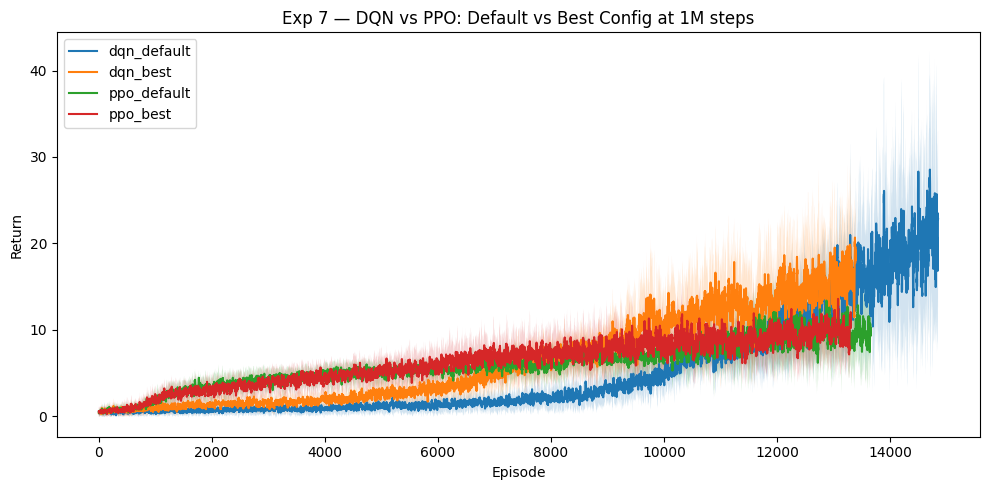


 Exp 7: DQN vs PPO — Sample Efficiency
  Config                          Final Return             AUC
  ----------------------------------------------------------
  dqn_default                   22.83 +/- 4.99       5.44 +/- 0.15  
  dqn_best                      18.20 +/- 2.48       6.27 +/- 0.17  
  ppo_default                    9.65 +/- 1.52       6.04 +/- 0.37  
  ppo_best                      11.15 +/- 2.35       6.24 +/- 0.25  

=== Heatmap: dqn_default ===


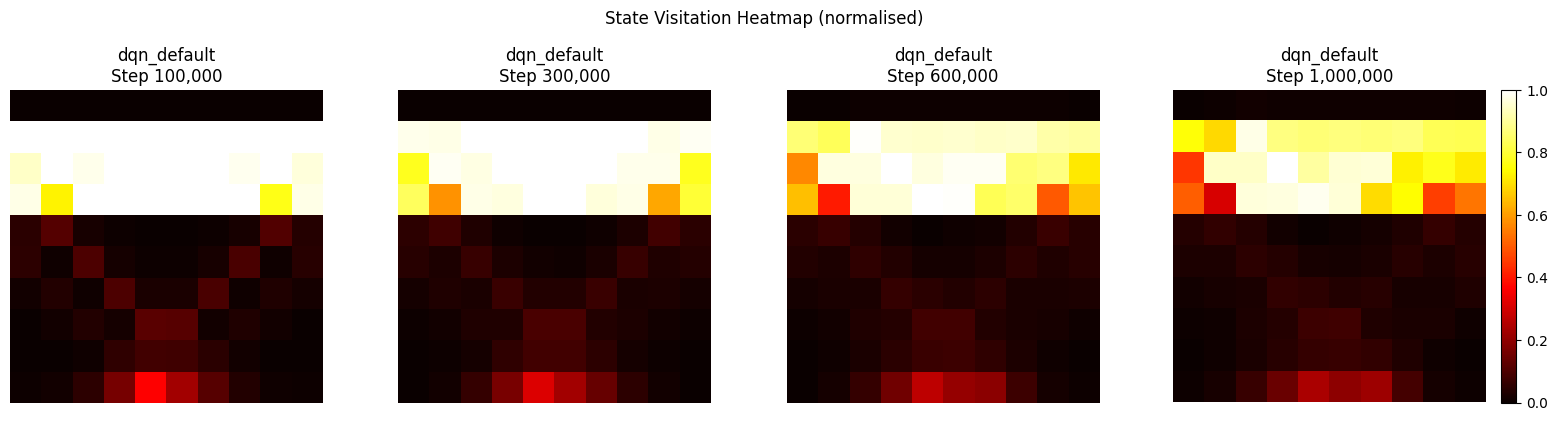


=== Heatmap: dqn_best ===


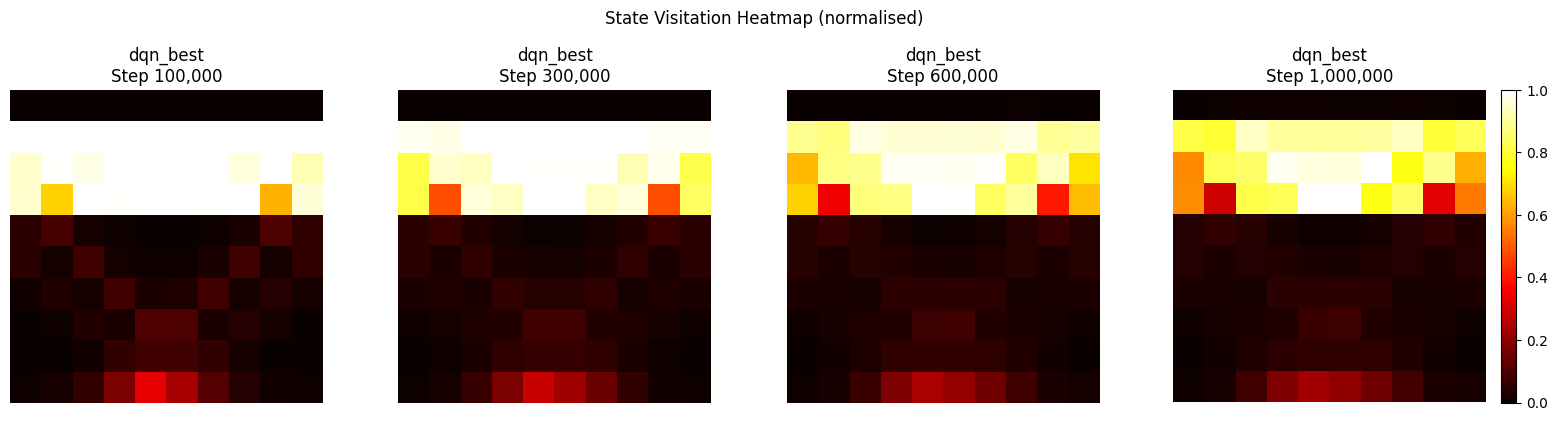


=== Heatmap: ppo_default ===


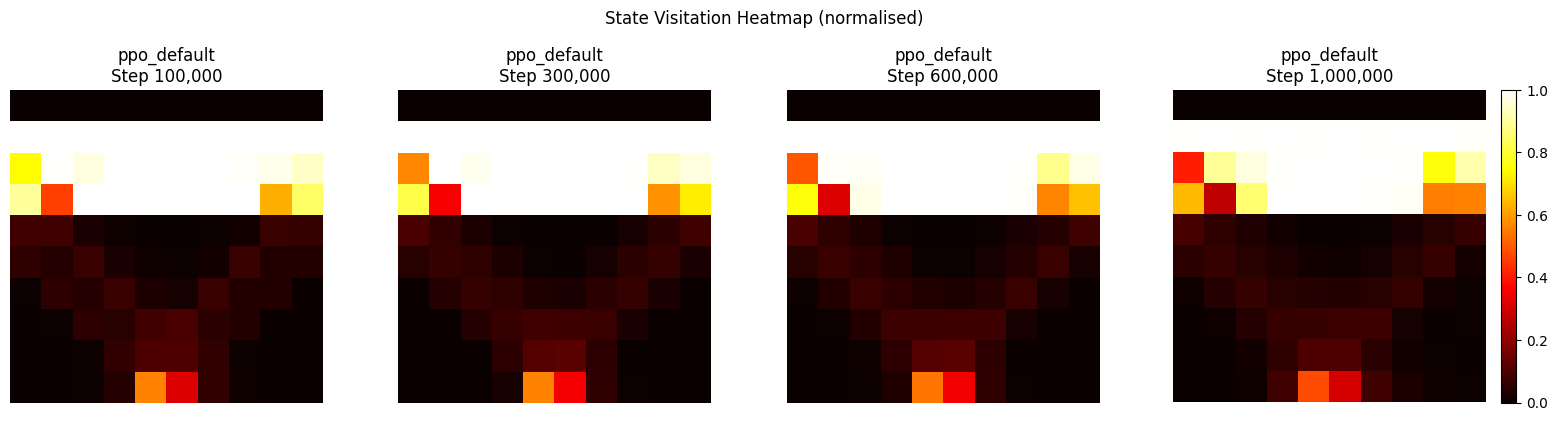


=== Heatmap: ppo_best ===


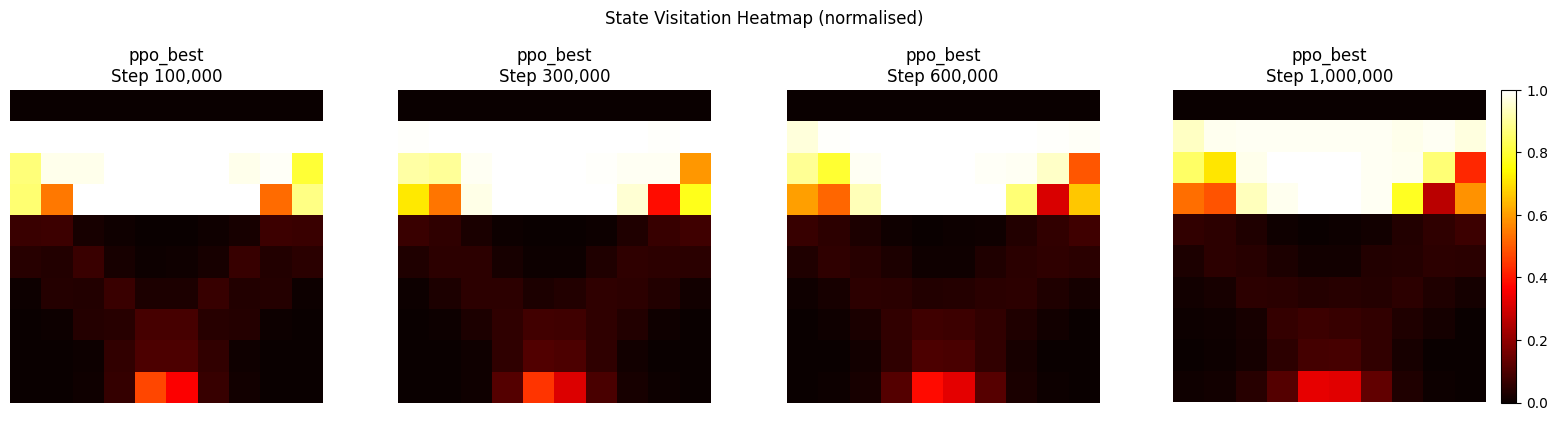

In [8]:
# Exp 7 — Confronto finale DQN vs PPO a 1M step
# Four configurations:
#   dqn_default : standard hyperparameters
#   dqn_best    : best combined hyperparameters from Exp 1, 2, 5
#   ppo_default : standard hyperparameters
#   ppo_best    : best combined hyperparameters from Exp 3, 4, 6
#
# Questions:
#   1. Does DQN or PPO perform better at 1M steps?
#   2. Do optimised hyperparameters beat the defaults?

TOTAL_STEPS_1M     = 1_000_000
HEATMAP_SNAPSHOTS  = [100_000, 300_000, 600_000, 1_000_000]
SEEDS_7            = [0, 1, 2]

# ── Configurations ────────────────────────────────────────────────────────────
dqn_default_cfg = {
    "game": GAME, "total_steps": TOTAL_STEPS_1M,
    "batch_size": 32, "buffer_size": 100_000,
    "lr": 1e-4, "gamma": 0.99,
    "eps_start": 1.0, "eps_end": 0.01, "eps_decay_steps": 250_000,
    "target_update_freq": 1000,
    "snapshot_steps": HEATMAP_SNAPSHOTS,
}

dqn_best_cfg = {
    "game": GAME, "total_steps": TOTAL_STEPS_1M,
    "batch_size": 32, "buffer_size": 100_000,   # Exp 2: standard already optimal
    "lr": 1e-4, "gamma": 0.99,
    "eps_start": 0.5,   "eps_end": 0.01,         # Exp 1: eps_conservative
    "eps_decay_steps": 250_000,
    "target_update_freq": 10_000,                 # Exp 5: low_freq
    "snapshot_steps": HEATMAP_SNAPSHOTS,
}

ppo_default_cfg = {
    "game": GAME, "total_steps": TOTAL_STEPS_1M,
    "n_steps": 128, "n_epochs": 4, "batch_size": 32,
    "lr": 2.5e-4, "gamma": 0.99,
    "gae_lambda": 0.95,   # Exp 6: already optimal
    "clip_coef":  0.2,    # standard
    "ent_coef":   0.01,   # standard
    "vf_coef": 0.5, "max_grad_norm": 0.5,
    "snapshot_steps": HEATMAP_SNAPSHOTS,
}

ppo_best_cfg = {
    "game": GAME, "total_steps": TOTAL_STEPS_1M,
    "n_steps": 128, "n_epochs": 4, "batch_size": 32,
    "lr": 2.5e-4, "gamma": 0.99,
    "gae_lambda": 0.95,   # Exp 6: already optimal
    "clip_coef":  0.1,    # Exp 4: tight_clip
    "ent_coef":   0.05,   # Exp 3: high_entropy
    "vf_coef": 0.5, "max_grad_norm": 0.5,
    "snapshot_steps": HEATMAP_SNAPSHOTS,
}

# ── Training ──────────────────────────────────────────────────────────────────
configs = [
    ("dqn", "default", dqn_default_cfg, train_dqn),
    ("dqn", "best",    dqn_best_cfg,    train_dqn),
    ("ppo", "default", ppo_default_cfg, train_ppo),
    ("ppo", "best",    ppo_best_cfg,    train_ppo),
]

exp7          = {}   # {label: [returns_per_seed]}
exp7_trackers = {}   # {label: tracker} — only seed=0 for heatmaps

for algo, variant, base_cfg, train_fn in configs:
    label = f"{algo}_{variant}"
    exp7[label] = []

    for seed in SEEDS_7:
        cached = load_run("exp7", label, seed)
        if cached is not None:
            print(f"\n[SKIP] exp7 | {label} | seed={seed} — already completed")
            exp7[label].append(cached)
            continue

        cfg = {**base_cfg, "seed": seed}
        print(f"\n[Exp7] {label} | seed={seed}")
        rets, tracker = train_fn(
            cfg,
            run_name=f"{label}_s{seed}_1M",
            use_wandb=True,
        )
        exp7[label].append(rets)
        save_run("exp7", label, seed, rets)

        # Save tracker only for seed=0 (heatmaps)
        if seed == 0:
            exp7_trackers[label] = tracker

# ── Results ───────────────────────────────────────────────────────────────────
plot_returns_with_std(
    exp7,
    title="Exp 7 — DQN vs PPO: Default vs Best Config at 1M steps"
)
sample_efficiency_summary(exp7, "Exp 7: DQN vs PPO — Sample Efficiency")

# ── Heatmaps ──────────────────────────────────────────────────────────────────
for label, tracker in exp7_trackers.items():
    print(f"\n=== Heatmap: {label} ===")
    tracker.plot_snapshots(label)

In [21]:
# Final Summary

print("FINAL SUMMARY — All Experiments")

print("""
Exp 1: DQN Epsilon Scheduling
  eps_aggressive               6.40 +/- 1.45
  eps_standard                12.88 +/- 2.33
  eps_conservative            17.52 +/- 2.70  <- BEST

Exp 2: DQN Replay Buffer Ablation
  no_buffer                    0.22 +/- 0.24
  small_buffer                 8.50 +/- 0.53
  standard_buffer             11.98 +/- 2.33  <- BEST

Exp 3: PPO Entropy Bonus
  no_entropy                   5.57 +/- 0.30
  low_entropy                  5.70 +/- 0.37
  std_entropy                  7.75 +/- 1.28
  high_entropy                 9.33 +/- 0.61  <- BEST

Exp 4: PPO Clip Parameter Ablation
  no_clip                      6.95 +/- 1.08
  tight_clip                   8.63 +/- 0.34  <- BEST
  std_clip                     5.73 +/- 0.32
  loose_clip                   5.35 +/- 0.27

Exp 5: DQN Target Update Frequency
  high_freq                   12.52 +/- 0.20
  std_freq                     9.67 +/- 1.82
  low_freq                    12.75 +/- 1.09  <- BEST

Exp 6: PPO GAE Lambda
  lambda_0                     4.28 +/- 1.07
  lambda_095                   6.87 +/- 1.17  <- BEST
  lambda_1                     5.78 +/- 0.49

Exp 7: DQN vs PPO — Default vs Best at 1M steps
  Config                    Final Return        AUC
  dqn_default              22.83 +/- 4.99    5.44 +/- 0.15
  dqn_best                 18.20 +/- 2.48    6.27 +/- 0.17
  ppo_default               9.65 +/- 1.52    6.04 +/- 0.37
  ppo_best                 11.15 +/- 2.35    6.24 +/- 0.25
""")

FINAL SUMMARY — All Experiments

Exp 1: DQN Epsilon Scheduling
  eps_aggressive               6.40 +/- 1.45
  eps_standard                12.88 +/- 2.33
  eps_conservative            17.52 +/- 2.70  <- BEST

Exp 2: DQN Replay Buffer Ablation
  no_buffer                    0.22 +/- 0.24
  small_buffer                 8.50 +/- 0.53
  standard_buffer             11.98 +/- 2.33  <- BEST

Exp 3: PPO Entropy Bonus
  no_entropy                   5.57 +/- 0.30
  low_entropy                  5.70 +/- 0.37
  std_entropy                  7.75 +/- 1.28
  high_entropy                 9.33 +/- 0.61  <- BEST

Exp 4: PPO Clip Parameter Ablation
  no_clip                      6.95 +/- 1.08
  tight_clip                   8.63 +/- 0.34  <- BEST
  std_clip                     5.73 +/- 0.32
  loose_clip                   5.35 +/- 0.27

Exp 5: DQN Target Update Frequency
  high_freq                   12.52 +/- 0.20
  std_freq                     9.67 +/- 1.82
  low_freq                    12.75 +/- 1.09  <-